# Imaginary time evolution of finite PEPS: simple update and full update
We find the ground state of the two-dimensional transverse field Ising model on a finite $L \times L$ lattice by evolving a projected entangled pair state (PEPS) in imaginary time,
$$
|\psi(\tau)\rangle = \frac{e^{-\tau H}|\psi(0)\rangle}{\|e^{-\tau H}|\psi(0)\rangle\|} \xrightarrow{\tau\to\infty} |\psi_0\rangle .
$$
The evolution operator is split into two-site gates (Trotter decomposition). Every gate increases the dimension of the bond it acts on from $D$ to $dD$, so the bond has to be **truncated** back to $D$ after every gate. The best truncation of a bond depends on the rest of the network, the **environment** of the bond. The three algorithms of this notebook differ only in what they use as the environment:

| | environment of the bond | cost of one bond update |
|---|---|---|
| **simple update (SU) without singular values** | none: an SVD of the two tensors alone | $\mathcal{O}(D^5)$ |
| **simple update (SU) with singular values** | the singular values $\lambda$ on the neighboring bonds | $\mathcal{O}(D^5)$ |
| **full update (FU)** | the whole network, contracted with boundary MPS of bond dimension $\chi$ | $\mathcal{O}(\chi^3 D^4 + \chi^2 D^6)$ |

We follow chapter 4 of [M. Schneider, *The Hubbard model on a honeycomb lattice with fermionic tensor networks*, dissertation, Humboldt-Universität zu Berlin (2022)], cited as [dissertation] below, for a bosonic PEPS on the square lattice. Finally we compare the three updates with each other and with the variational optimization of `PEPS_variational.ipynb`.

The time evolution of an MPS is shown in `ImaginaryTimeEvolution.ipynb`; the boundary MPS, the measurement of energies and the variational optimization are explained in `PEPS_variational.ipynb`.

Contents:
1. Model, PEPS, boundary MPS and variational optimization (from `PEPS_variational.ipynb`)
2. Trotter decomposition
3. Truncating a bond: the role of the environment
4. Simple update without singular values
5. Simple update with singular values
6. Full update
7. Protocol: decreasing time step, convergence criterion and energy estimator
8. One truncation with three environments
9. Results
10. Summary

## Install
Import Cytnx, see https://cytnx-dev.github.io/Cytnx/

In [1]:
# The following 2 lines are only needed if you installed Cytnx from source
import sys
sys.path.insert(0,'/home/manuel/Cytnx_lib') # change to your installation path

# The tensors in this notebook are small, so multithreading only adds overhead, and idle
# OpenMP threads should sleep instead of spinning. Both must be set before cytnx is imported.
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OMP_WAIT_POLICY"] = "PASSIVE"

import cytnx
import json
import math
import time
import matplotlib.pyplot as plt
print(cytnx.__version__)

1.1.1


## 1. Model, PEPS, boundary MPS and variational optimization
The following code is taken unchanged from `PEPS_variational.ipynb`, where it is explained and tested:
* the transverse field Ising model $H = -J \sum_{\langle i,j \rangle} \sigma^z_i \sigma^z_j - h \sum_i \sigma^x_i$ as a list of terms, and exact diagonalization for up to $4 \times 4$ sites;
* the PEPS with global labels: the tensor of site $(x, y)$ has the legs `kh(x,y)` (left), `kh(x+1,y)` (right), `kv(x,y)` (up), `kv(x,y+1)` (down) and `p(x,y)` (physical);
* boundary MPS of bond dimension $\chi$, row strips, and the energy measurement `measure`;
* the variational optimization `optimize_damped` (site by site, generalized eigenvalue problem with damped updates and cutoff stages $10^{-4}$, $10^{-6}$).

In [2]:
def pauli(name):
    if name == "x":
        return cytnx.physics.pauli("x").real()
    if name == "z":
        return cytnx.physics.pauli("z").real()
    if name == "1":
        return cytnx.eye(2)
    raise ValueError(name)

def ising_terms(Lx, Ly, J, h):
    """List of terms (coefficient, {(x, y): operator name}); each term is a product of
    single-site operators."""
    terms = []
    for y in range(Ly):
        for x in range(Lx):
            if x + 1 < Lx:
                terms.append((-J, {(x, y): "z", (x + 1, y): "z"}))
            if y + 1 < Ly:
                terms.append((-J, {(x, y): "z", (x, y + 1): "z"}))
            terms.append((-h, {(x, y): "x"}))
    return terms

class IsingOp(cytnx.LinOp):
    """H acting on a state vector psi of length 2^V (V = Lx * Ly). Site (x, y) has the
    index i = x + Lx * y and is the i-th most significant bit of the basis state.

    Terms that consist of sz only are diagonal; their sum is computed once. A term sx_i
    flips bit i: reshaped to (2^i, 2, 2^(V-1-i)), psi is multiplied by sx on the middle
    index."""

    def __init__(self, Lx, Ly, terms):
        V = Lx * Ly
        cytnx.LinOp.__init__(self, "mv", 2 ** V)
        self.V = V
        self.diagonal = cytnx.zeros(2 ** V)
        self.flips = []
        for c, ops in terms:
            if all(o == "z" for o in ops.values()):
                v = cytnx.ones(1)
                for i in range(V):
                    d = cytnx.ones(2)
                    if ops.get((i % Lx, i // Lx)) == "z":
                        d[1] = -1
                    v = cytnx.linalg.Kron(v, d)
                self.diagonal += c * v
            elif len(ops) == 1 and list(ops.values())[0] == "x":
                (x, y), = ops.keys()
                self.flips.append((c, x + Lx * y))
            else:
                raise ValueError("only products of sz and single sx terms are implemented")
        self.sx = pauli("x")

    def matvec(self, psi):
        out = self.diagonal * psi
        for c, i in self.flips:
            psi3 = psi.reshape(2 ** i, 2, 2 ** (self.V - 1 - i))
            flipped = cytnx.linalg.Tensordot(psi3, self.sx, [1], [0]).permute(0, 2, 1).contiguous()
            out += c * flipped.reshape(2 ** self.V)
        return out

def exact_ground_state(Lx, Ly, terms):
    """Ground state energy and vector by Lanczos (ARPACK); feasible up to about 4 x 4."""
    Hop = IsingOp(Lx, Ly, terms)
    psi = cytnx.random.uniform(2 ** (Lx * Ly), -1, 1, seed=0)
    E, psi0 = cytnx.linalg.Lanczos(Hop, psi, which="SA", Maxiter=10000, CvgCrit=1e-12, k=1, is_V=True)
    return E[0].item(), psi0

def dense_energy(psi, Lx, Ly, terms):
    """<psi|H|psi> / <psi|psi> for a state vector psi."""
    Hpsi = IsingOp(Lx, Ly, terms).matvec(psi)
    return cytnx.linalg.Vectordot(psi, Hpsi).item() / cytnx.linalg.Vectordot(psi, psi).item()

In [3]:
def kh(x, y): return f"kh{x}_{y}"

def kv(x, y): return f"kv{x}_{y}"

def bh(x, y): return f"bh{x}_{y}"

def bv(x, y): return f"bv{x}_{y}"

def phys(x, y): return f"p{x}_{y}"

class PEPS:
    """Finite PEPS on an Lx x Ly lattice with open boundaries.

    The tensor of site (x, y) has the legs kh(x,y) (left, incoming), kh(x+1,y) (right,
    outgoing), kv(x,y) (up, incoming), kv(x,y+1) (down, outgoing) and phys(x,y)
    (incoming). Legs at the lattice boundary have dimension 1."""

    def __init__(self, Lx, Ly, D, d=2):
        self.Lx, self.Ly, self.D, self.d = Lx, Ly, D, d
        self.A = {}
        self.bra_cache = {}

    def dims(self, x, y, D=None):
        D = self.D if D is None else D
        return [1 if x == 0 else D, 1 if x == self.Lx - 1 else D,
                1 if y == 0 else D, 1 if y == self.Ly - 1 else D, self.d]

    def labels(self, x, y):
        return [kh(x, y), kh(x + 1, y), kv(x, y), kv(x, y + 1), phys(x, y)]

    def set_tensor(self, x, y, data):
        """Set the tensor of site (x, y) from a Tensor of shape (left, right, up, down, d)."""
        Dl, Dr, Du, Dd, d = data.shape()
        bonds = [cytnx.Bond(Dl, cytnx.BD_KET), cytnx.Bond(Dr, cytnx.BD_BRA),
                 cytnx.Bond(Du, cytnx.BD_KET), cytnx.Bond(Dd, cytnx.BD_BRA), cytnx.Bond(d, cytnx.BD_KET)]
        A = cytnx.UniTensor(bonds, labels=self.labels(x, y), rowrank=4, dtype=data.dtype())
        A.put_block(data.contiguous())
        self.A[(x, y)] = A
        self.bra_cache.pop((x, y), None)

    def data(self, x, y):
        return self.A[(x, y)].permute(self.labels(x, y)).get_block().contiguous()

    def ket(self, x, y, op=None):
        """Ket tensor of site (x, y), with the single-site operator `op` applied if given."""
        A = self.A[(x, y)]
        if op is None:
            return A
        return cytnx.Contract(site_op(op, x, y), A).relabel(phys(x, y) + "'", phys(x, y))

    def bra(self, x, y):
        """Complex conjugate of the ket tensor; its virtual legs carry the bra labels."""
        if (x, y) not in self.bra_cache:
            old = [kh(x, y), kh(x + 1, y), kv(x, y), kv(x, y + 1)]
            new = [bh(x, y), bh(x + 1, y), bv(x, y), bv(x, y + 1)]
            self.bra_cache[(x, y)] = self.A[(x, y)].Dagger().relabel(old, new)
        return self.bra_cache[(x, y)]

def site_op(name, x, y):
    """Single-site operator with legs phys(x,y)' (incoming) and phys(x,y) (outgoing)."""
    O = cytnx.UniTensor([cytnx.Bond(2, cytnx.BD_KET), cytnx.Bond(2, cytnx.BD_BRA)],
                        labels=[phys(x, y) + "'", phys(x, y)], rowrank=1)
    O.put_block(pauli(name))
    return O

def product_peps(Lx, Ly, state, noise=0.0, seed=0):
    """D = 1 PEPS of the product state `state` (a list of d amplitudes) plus random noise."""
    peps = PEPS(Lx, Ly, 1, len(state))
    for y in range(Ly):
        for x in range(Lx):
            data = cytnx.zeros([1, 1, 1, 1, len(state)])
            for s, a in enumerate(state):
                data[0, 0, 0, 0, s] = a
            if noise > 0:
                data += noise * cytnx.random.uniform([1, 1, 1, 1, len(state)], -1, 1, seed=seed + x + Lx * y)
            peps.set_tensor(x, y, data / data.norm())
    return peps

def grow_bond_dimension(peps, D, noise=0.1, seed=1):
    """Return a PEPS with bond dimension D > peps.D: the old tensors are embedded in the
    larger ones, and all entries get random noise of relative size `noise`."""
    new = PEPS(peps.Lx, peps.Ly, D, peps.d)
    for (x, y), A in peps.A.items():
        old = peps.data(x, y)
        data = noise * cytnx.random.uniform(new.dims(x, y), -1, 1, seed=seed + x + peps.Lx * y)
        Dl, Dr, Du, Dd, d = old.shape()
        data[:Dl, :Dr, :Du, :Dd, :] += old
        new.set_tensor(x, y, data / data.norm())
    return new

def copy_peps(peps):
    new = PEPS(peps.Lx, peps.Ly, peps.D, peps.d)
    new.A = {site: A.clone() for site, A in peps.A.items()}
    return new

def peps_to_state(peps):
    """Contract all ket tensors (exponential cost; only for tests on small lattices)."""
    psi = None
    for y in range(peps.Ly):
        for x in range(peps.Lx):
            psi = peps.ket(x, y) if psi is None else cytnx.Contract(psi, peps.ket(x, y))
    labels = [phys(x, y) for y in range(peps.Ly) for x in range(peps.Lx)]
    rest = [l for l in psi.labels() if l not in labels]
    return psi.permute(labels + rest).get_block().contiguous().reshape(2 ** len(labels))

In [4]:
class Boundary:
    """Boundary MPS that approximates the ket-bra network of the rows above (side "top")
    or below (side "bottom") row `row`.

    tensors[x] has the chain legs prefix+x and prefix+(x+1) and two legs that connect to
    the ket and bra tensors of row `row`: the up legs kv(x,row), bv(x,row) for a top
    boundary, the down legs kv(x,row+1), bv(x,row+1) for a bottom boundary. The boundary
    is normalized; its norm is kept as exp(lognorm)."""

    def __init__(self, side, row, tensors, lognorm=0.0):
        self.side, self.row, self.tensors, self.lognorm = side, row, tensors, lognorm
        self.prefix = "T" if side == "top" else "B"

def vertical_legs(side, x, row):
    """Labels of the ket and bra legs of row `row` that a boundary of this side attaches to."""
    y = row if side == "top" else row + 1
    return kv(x, y), bv(x, y)

def trivial_boundary(peps, side):
    """Boundary outside the lattice: every tensor is the number 1, all legs have dimension 1."""
    row = 0 if side == "top" else peps.Ly - 1
    prefix = "T" if side == "top" else "B"
    tensors = []
    for x in range(peps.Lx):
        lk, lb = vertical_legs(side, x, row)
        bonds = [cytnx.Bond(1, cytnx.BD_KET), cytnx.Bond(1, cytnx.BD_BRA),
                 peps.ket(x, row).bond(lk).redirect(), peps.bra(x, row).bond(lb).redirect()]
        T = cytnx.UniTensor(bonds, labels=[f"{prefix}{x}", f"{prefix}{x+1}", lk, lb], rowrank=2)
        T.at([0, 0, 0, 0]).value = 1
        tensors.append(T)
    return Boundary(side, row, tensors)

def trivial_env(*legs):
    """Environment of dimension 1 that closes the given (tensor, label) legs."""
    bonds = [T.bond(label).redirect() for T, label in legs]
    E = cytnx.UniTensor(bonds, labels=[label for _, label in legs], rowrank=len(bonds))
    E.at([0] * len(bonds)).value = 1
    return E

def right_canonical(w, prefix):
    """Bring the MPS w (chain legs prefix+x) into right-canonical form and normalize it."""
    L = len(w)
    for x in range(L - 1, 0, -1):
        others = [l for l in w[x].labels() if l != f"{prefix}{x}"]
        T = w[x].permute([f"{prefix}{x}"] + others, rowrank=1)
        S, U, V = cytnx.linalg.Svd(T)
        w[x] = V.relabel("_aux_R", f"{prefix}{x}")
        w[x - 1] = cytnx.Contract(w[x - 1], cytnx.Contract(U, S)).relabel("_aux_R", f"{prefix}{x}")
    w[0] = w[0] / w[0].norm()
    return w

def truncated_svd(T, chi, err=1e-14):
    """SVD keeping at most chi singular values and dropping those below err relative to the
    norm of T. Svd_truncate compares the singular values with err directly, so T is
    normalized first and S is scaled back afterwards."""
    norm = T.norm()
    S, U, V = cytnx.linalg.Svd_truncate(T / norm, keepdim=chi, err=err)
    return S * norm, U, V

def absorb_row(boundary, peps, ops, chi, guess=None, maxit=10, tol=1e-10):
    """Add the row next to `boundary` (ket and bra layer, with the single-site operators
    ops = {(x, y): name} applied to the ket layer) and approximate the result by a new
    boundary MPS with bond dimension chi.

    The new boundary w is found by a two-site variational fit of the network v = (old
    boundary, ket row, bra row), sweeping from left to right and back, like apply_mpo in
    the time evolution notebook. The fit stops after `maxit` iterations (one right and one
    left sweep each) or when f = |<w|v>| / |w| changes by at most tol between two half
    sweeps. `guess` is an initial boundary (e.g. from the previous sweep), else w starts
    random."""
    side, r, P = boundary.side, boundary.row, boundary.prefix
    Lx = peps.Lx
    new_row = r + 1 if side == "top" else r - 1
    old = boundary.tensors
    K = [peps.ket(x, r, ops.get((x, r))) for x in range(Lx)]
    Br = [peps.bra(x, r) for x in range(Lx)]
    out = [vertical_legs(side, x, new_row) for x in range(Lx)]   # open legs of the new boundary

    # ---- initial guess w (chain legs N0..N{Lx}) in right-canonical form
    w = None
    if guess is not None:
        w = [T.relabel([f"{P}{x}", f"{P}{x+1}"], [f"N{x}", f"N{x+1}"]) for x, T in enumerate(guess.tensors)]
        if any(w[x].bond(out[x][0]).dim() != K[x].bond(out[x][0]).dim() for x in range(Lx)):
            w = None   # bond dimension of the PEPS changed
    if w is None:
        phys_dims = [K[x].bond(out[x][0]).dim() * Br[x].bond(out[x][1]).dim() for x in range(Lx)]
        chain = [1]
        for x in range(1, Lx):
            chain.append(min(chi, math.prod(phys_dims[:x]), math.prod(phys_dims[x:])))
        chain.append(1)
        w = []
        for x in range(Lx):
            bonds = [cytnx.Bond(chain[x], cytnx.BD_KET), cytnx.Bond(chain[x + 1], cytnx.BD_BRA),
                     K[x].bond(out[x][0]).clone(), Br[x].bond(out[x][1]).clone()]
            T = cytnx.UniTensor(bonds, labels=[f"N{x}", f"N{x+1}", out[x][0], out[x][1]], rowrank=2)
            cytnx.random.uniform_(T, -1, 1, seed=x)
            w.append(T)
    w = right_canonical(w, "N")
    conj = lambda T, x: T.Dagger().relabel([f"N{x}", f"N{x+1}"], [f"C{x}", f"C{x+1}"])
    cw = [conj(w[x], x) for x in range(Lx)]

    def column(E, x):
        E = cytnx.Contract(E, old[x])
        E = cytnx.Contract(E, K[x])
        E = cytnx.Contract(E, Br[x])
        return E

    # ---- environments: env[j] covers the columns < j (left) or >= j (right)
    env = [None] * (Lx + 1)
    env[0] = trivial_env((old[0], f"{P}0"), (K[0], kh(0, r)), (Br[0], bh(0, r)), (cw[0], "C0"))
    env[Lx] = trivial_env((old[Lx - 1], f"{P}{Lx}"), (K[Lx - 1], kh(Lx, r)), (Br[Lx - 1], bh(Lx, r)),
                          (cw[Lx - 1], f"C{Lx}"))
    for x in range(Lx - 1, 1, -1):
        env[x] = cytnx.Contract(column(env[x + 1], x), cw[x])

    def theta(x, first, second, other):
        """Two-site tensor of sites x, x+1: `first` is the environment extended by the
        column it was contracted with, `second` the other column, `other` the opposite
        environment."""
        T = cytnx.Contract(column(first, second), other)
        T.relabel_([f"C{x}", f"C{x+2}"], [f"N{x}", f"N{x+2}"])
        return T.permute([f"N{x}", out[x][0], out[x][1], out[x + 1][0], out[x + 1][1], f"N{x+2}"], rowrank=3)

    fids = []
    for sweep in range(2 * maxit):
        if sweep % 2 == 0:   # right sweep
            for x in range(Lx - 1):
                left = column(env[x], x)   # reused for the new left environment
                S, U, V = truncated_svd(theta(x, left, x + 1, env[x + 2]), chi)
                w[x] = U.relabel("_aux_L", f"N{x+1}")
                w[x + 1] = cytnx.Contract(S, V).relabel("_aux_L", f"N{x+1}")
                cw[x] = conj(w[x], x)
                env[x + 1] = cytnx.Contract(left, cw[x])
            center = Lx - 1
        else:                # left sweep
            for x in range(Lx - 2, -1, -1):
                right = column(env[x + 2], x + 1)   # reused for the new right environment
                S, U, V = truncated_svd(theta(x, right, x, env[x]), chi)
                w[x + 1] = V.relabel("_aux_R", f"N{x+1}")
                w[x] = cytnx.Contract(U, S).relabel("_aux_R", f"N{x+1}")
                cw[x + 1] = conj(w[x + 1], x + 1)
                env[x + 1] = cytnx.Contract(right, cw[x + 1])
            center = 0
        norm = w[center].norm()
        cw[center] = conj(w[center], center)
        overlap = cytnx.Contract(cytnx.Contract(column(env[center], center), cw[center]), env[center + 1]).item()
        fids.append(abs(overlap) / norm)
        if sweep > 0 and abs(fids[-1] - fids[-2]) <= tol * fids[-1]:
            break
    w[center] = w[center] / norm
    tensors = [T.relabel([f"N{x}", f"N{x+1}"], [f"{P}{x}", f"{P}{x+1}"]) for x, T in enumerate(w)]
    return Boundary(side, new_row, tensors, boundary.lognorm + math.log(norm))

class Strip:
    """The network of one row r between a top and a bottom boundary, with the single-site
    operators `ops` (only those in row r are used) applied to the ket layer.

    SL[x] contracts the columns < x, SR[x] the columns >= x. The environment of site (x, r)
    is SL[x] . top[x] . bottom[x] . SR[x+1]: the network with the ket and bra tensor of
    the site cut out, an 8-leg tensor."""

    def __init__(self, peps, r, top, bottom, ops):
        self.peps, self.r, self.top, self.bottom = peps, r, top, bottom
        self.ops = {x: o for (x, y), o in ops.items() if y == r}
        Lx = peps.Lx
        self.SL, self.SR = [None] * (Lx + 1), [None] * (Lx + 1)
        T, B = top.tensors, bottom.tensors
        K0, KL = self.ket(0), self.ket(Lx - 1)
        self.SL[0] = trivial_env((T[0], "T0"), (K0, kh(0, r)), (peps.bra(0, r), bh(0, r)), (B[0], "B0"))
        self.SR[Lx] = trivial_env((T[Lx - 1], f"T{Lx}"), (KL, kh(Lx, r)), (peps.bra(Lx - 1, r), bh(Lx, r)),
                                  (B[Lx - 1], f"B{Lx}"))
        for x in range(Lx):
            self.update_left(x)
        for x in range(Lx - 1, -1, -1):
            self.update_right(x)

    def ket(self, x):
        return self.peps.ket(x, self.r, self.ops.get(x))

    def column(self, E, x):
        E = cytnx.Contract(E, self.top.tensors[x])
        E = cytnx.Contract(E, self.ket(x))
        E = cytnx.Contract(E, self.peps.bra(x, self.r))
        return cytnx.Contract(E, self.bottom.tensors[x])

    def update_left(self, x):
        """Recompute SL[x+1] from SL[x], e.g. after the tensor of site (x, r) changed."""
        self.SL[x + 1] = self.column(self.SL[x], x)

    def update_right(self, x):
        """Recompute SR[x] from SR[x+1]."""
        self.SR[x] = self.column(self.SR[x + 1], x)

    def value(self):
        """Full contraction of the strip (relative to exp(top.lognorm + bottom.lognorm))."""
        return cytnx.Contract(self.SL[0], self.SR[0]).item()

    def site_env(self, x):
        E = cytnx.Contract(self.SL[x], self.top.tensors[x])
        E = cytnx.Contract(E, self.bottom.tensors[x])
        return cytnx.Contract(E, self.SR[x + 1])

def env_matrix(E, x, r):
    """Environment as a matrix: rows are the bra legs, columns the ket legs of site (x, r)."""
    bra = [bh(x, r), bh(x + 1, r), bv(x, r), bv(x, r + 1)]
    ket = [kh(x, r), kh(x + 1, r), kv(x, r), kv(x, r + 1)]
    M = E.permute(bra + ket).get_block().contiguous()
    m = math.prod(M.shape()[:4])
    return M.reshape(m, m)

def term_rows(ops):
    return [y for (_, y) in ops]

def measure(peps, terms, chi, fit=None):
    """Energy E = sum_t <h_t> and norm deviation.

    Each term is evaluated in the row of its upper site r, with the norm boundaries above
    and the norm boundary (or for a vertical bond its own boundary) below, and divided by
    the norm of the same row, so that truncation errors partly cancel. The norm deviation
    is the relative standard deviation of the norms of all rows, which would all be equal
    without truncation."""
    fit = fit or {}
    tops, bottoms = {}, {}
    b = {"norm": trivial_boundary(peps, "top")}
    for r in range(peps.Ly):
        tops[r] = b["norm"]
        if r < peps.Ly - 1:
            b = {"norm": absorb_row(b["norm"], peps, {}, chi, **fit)}
    b = {"norm": trivial_boundary(peps, "bottom")}
    for r in range(peps.Ly - 1, -1, -1):
        bottoms[r] = b["norm"]
        if r > 0:
            b = {"norm": absorb_row(b["norm"], peps, {}, chi, **fit)}
    lognorms = []
    for r in range(peps.Ly):
        value = Strip(peps, r, tops[r], bottoms[r], {}).value()
        lognorms.append(math.log(abs(value)) + tops[r].lognorm + bottoms[r].lognorm)
    E = 0.0
    for c, ops in terms:
        r = min(term_rows(ops))
        bottom = bottoms[r]
        if max(term_rows(ops)) > r:   # vertical bond: the lower operator goes into the bottom boundary
            bottom = absorb_row(bottoms[r + 1], peps, ops, chi, **fit)
        value = Strip(peps, r, tops[r], bottom, ops).value()
        E += c * value * math.exp(tops[r].lognorm + bottom.lognorm - lognorms[r])
    mean = sum(lognorms) / len(lognorms)
    norms = [math.exp(l - mean) for l in lognorms]
    avg = sum(norms) / len(norms)
    deviation = math.sqrt(sum((n - avg) ** 2 for n in norms) / max(len(norms) - 1, 1)) / avg
    return E, deviation

def next_boundaries(bounds, peps, terms, chi, cache, fit):
    """Absorb the row next to the boundaries `bounds` = {"norm": Boundary, i: Boundary}.

    Term i gets its own boundary as soon as one of its operators lies in the absorbed rows;
    until then it shares the "norm" boundary. `cache` holds the boundaries of the previous
    sweep as initial guesses for the fit."""
    side, r = bounds["norm"].side, bounds["norm"].row
    new_row = r + 1 if side == "top" else r - 1
    out = {}
    key = (side, new_row, "norm")
    out["norm"] = absorb_row(bounds["norm"], peps, {}, chi, cache.get(key), **fit)
    cache[key] = out["norm"]
    for i, (c, ops) in enumerate(terms):
        rows = term_rows(ops)
        reached = min(rows) <= r if side == "top" else max(rows) >= r
        if not reached:
            continue
        source = bounds.get(i, bounds["norm"])
        key = (side, new_row, i)
        out[i] = absorb_row(source, peps, ops, chi, cache.get(key), **fit)
        cache[key] = out[i]
    return out

def all_boundaries(peps, terms, chi, side, cache, fit):
    """Boundaries of all rows for one side: result[r] = {"norm": ..., i: ...}."""
    if side == "top":
        rows = range(peps.Ly)
    else:
        rows = range(peps.Ly - 1, -1, -1)
    result = {}
    bounds = {"norm": trivial_boundary(peps, side)}
    for r in rows:
        result[r] = bounds
        if r != rows[-1]:
            bounds = next_boundaries(bounds, peps, terms, chi, cache, fit)
    return result

def row_strips(peps, terms, r, tops, bottoms):
    """Strips of row r for the norm and for every term, with the factors that bring all
    of them to the same normalization as the norm strip."""
    tn, bn = tops["norm"], bottoms["norm"]
    norm = Strip(peps, r, tn, bn, {})
    strips = []
    for i, (c, ops) in enumerate(terms):
        t, b = tops.get(i, tn), bottoms.get(i, bn)
        scale = math.exp(t.lognorm + b.lognorm - tn.lognorm - bn.lognorm)
        strips.append((c * scale, ops, Strip(peps, r, t, b, ops)))
    return norm, strips

In [5]:
def hermitian(M):
    return (M + M.permute(1, 0).Conj()) / 2

def solve_gep(Hm, Nm, cutoff=1e-12):
    """Lowest eigenpair of H x = E N x for a positive semi-definite N.

    N = U n U^dagger is diagonalized; eigenvalues n <= cutoff * max(n) are dropped, which
    removes the (numerical) kernel and negative norms. With W = U n^(-1/2) on the kept
    space, the problem becomes the ordinary Hermitian eigenvalue problem
    (W^dagger H W) y = E y, and x = W y. The inverse square root uses the element-wise
    pseudo-inverse cytnx.linalg.Inv(., clip)."""
    n, U = cytnx.linalg.Eigh(hermitian(Nm))
    m = n.shape()[0]
    nmax = n[m - 1].item()
    # a negative eigenvalue of N is an error of the boundary approximation; eigenvalues
    # of the same magnitude are not reliable either
    threshold = max(cutoff * nmax, -n[0].item())
    start = 0
    while start < m and n[start].item() <= threshold:
        start += 1
    if start == m:   # no reliable direction: the boundary approximation is too poor
        return float("nan"), None, 0
    Uk = U[:, start:].contiguous()
    sinv = cytnx.linalg.Inv(cytnx.linalg.Pow(n[start:].contiguous(), 0.5), math.sqrt(threshold))
    W = cytnx.linalg.Matmul(Uk, cytnx.linalg.Diag(sinv))
    Ht = cytnx.linalg.Matmul(W.permute(1, 0).Conj().contiguous(), cytnx.linalg.Matmul(hermitian(Hm), W))
    e, Y = cytnx.linalg.Eigh(hermitian(Ht))
    x = cytnx.linalg.Matmul(W, Y[:, 0:1].contiguous())
    return e[0].item(), x.reshape(-1), m - start

def optimize_site(peps, x, r, norm, strips, cutoff, alpha=1.0):
    """Replace the tensor of site (x, r) by the lowest solution of the GEP. For alpha < 1,
    the new tensor is the mixture of the old tensor and the GEP solution (damped_update,
    section 8), and the returned energy is the energy of the mixture."""
    Nm = cytnx.linalg.Kron(env_matrix(norm.site_env(x), x, r), pauli("1"))
    rest = None
    Hm = None
    for c, ops, strip in strips:
        Em = c * env_matrix(strip.site_env(x), x, r)
        if (x, r) in ops:   # the operator acts on the optimized site
            term = cytnx.linalg.Kron(Em, pauli(ops[(x, r)]))
            Hm = term if Hm is None else Hm + term
        else:
            rest = Em if rest is None else rest + Em
    term = cytnx.linalg.Kron(rest, pauli("1"))
    Hm = term if Hm is None else Hm + term
    E, vec, kept = solve_gep(Hm, Nm, cutoff)
    if vec is None:   # keep the current tensor
        return E, kept
    if alpha < 1:
        vec, E = damped_update(peps.data(x, r).reshape(-1), vec, Hm, Nm, alpha)
    data = vec.reshape(*peps.dims(x, r))
    peps.set_tensor(x, r, data / data.norm())
    return E, kept

def optimize_row(peps, terms, r, tops, bottoms, cutoff, reverse=False, alpha=1.0):
    norm, strips = row_strips(peps, terms, r, tops, bottoms)
    energies = []
    xs = range(peps.Lx - 1, -1, -1) if reverse else range(peps.Lx)
    for x in xs:
        E, kept = optimize_site(peps, x, r, norm, strips, cutoff, alpha)
        energies.append(E)
        for s in [norm] + [s for _, _, s in strips]:
            if reverse:
                s.update_right(x)
            else:
                s.update_left(x)
    return energies

def sweep(peps, terms, chi, direction, cache, fit, cutoff, alpha=1.0):
    """Optimize every site once. direction "down": rows from top to bottom (the bottom
    boundaries of all rows are computed first, the top boundaries move along with the
    optimized row); "up": the other way round. alpha < 1 mixes every new tensor with the
    old one (section 8)."""
    energies = []
    if direction == "down":
        bottoms = all_boundaries(peps, terms, chi, "bottom", cache, fit)
        tops = {"norm": trivial_boundary(peps, "top")}
        for r in range(peps.Ly):
            energies += optimize_row(peps, terms, r, tops, bottoms[r], cutoff, alpha=alpha)
            if r < peps.Ly - 1:
                tops = next_boundaries(tops, peps, terms, chi, cache, fit)
    else:
        tops = all_boundaries(peps, terms, chi, "top", cache, fit)
        bottoms = {"norm": trivial_boundary(peps, "bottom")}
        for r in range(peps.Ly - 1, -1, -1):
            energies += optimize_row(peps, terms, r, tops[r], bottoms, cutoff, reverse=True, alpha=alpha)
            if r > 0:
                bottoms = next_boundaries(bottoms, peps, terms, chi, cache, fit)
    return energies

def optimize(peps, terms, chi, maxsweeps=20, tol=1e-8, cutoff=1e-12, fit=None, verbose=False):
    """Variational ground state search: alternate downward and upward sweeps.

    After every sweep, the energy is measured independently with `measure`. The best state
    so far is kept; if the measured energy increases, the boundary approximation is not
    reliable enough for the last sweep, and we return to the best state and stop.
    Otherwise we stop when the relative change of the measured energy in one sweep is at
    most tol (tol=0 switches this off), or after maxsweeps sweeps.
    Returns a dictionary with the measured energies and norm deviations after every sweep,
    the GEP energies after every site update, the runtimes and the reason to stop."""
    fit = fit or {}
    cache = {}
    info = dict(energies=[], deviations=[], gep=[], runtimes=[], stop="maxsweeps")
    start = time.perf_counter()
    E, deviation = measure(peps, terms, chi, fit)
    best = (E, deviation, copy_peps(peps))
    for n in range(maxsweeps):
        direction = "down" if n % 2 == 0 else "up"
        info["gep"] += sweep(peps, terms, chi, direction, cache, fit, cutoff)
        E, deviation = measure(peps, terms, chi, fit)
        info["runtimes"].append(time.perf_counter() - start)
        if verbose:
            print(f"  sweep {n} ({direction}): E = {E:.10f}, E(GEP) = {info['gep'][-1]:.10f}, "
                  f"norm deviation {deviation:.1e}, {info['runtimes'][-1]:.1f} s")
        if E > best[0]:   # return to the best state
            info["stop"] = "energy increased" if E - best[0] > tol * abs(best[0]) else "converged"
            peps.A, peps.bra_cache = best[2].A, {}
            break
        converged = best[0] - E <= tol * abs(E)
        info["energies"].append(E)
        info["deviations"].append(deviation)
        best = (E, deviation, copy_peps(peps))
        if converged:
            info["stop"] = "converged"
            break
    if not info["energies"]:   # the first sweep did not lower the energy
        info["energies"].append(best[0])
        info["deviations"].append(best[1])
    return info

def damped_update(old, new, Hm, Nm, alpha):
    """Mixture (1 - alpha) old + alpha new of the old tensor and the GEP solution (vectors).

    Both are normalized with N_eff, so they describe states with the same norm, and the
    phase of `new` (for real tensors: its sign) is chosen such that the overlap
    <old|N_eff|new> is real and positive. Then the mixture moves from the old state towards
    the GEP solution on the shorter way, and the energy of the local problem decreases
    monotonically with alpha. Returns the mixture and its energy in the local problem."""
    H, N = hermitian(Hm), hermitian(Nm)
    def braket(a, M, b):
        return cytnx.linalg.Vectordot(a, cytnx.linalg.Dot(M, b), True).item()
    norm_old, norm_new = braket(old, N, old).real, braket(new, N, new).real
    if norm_old <= 0 or norm_new <= 0:   # the environment cannot measure the old state
        return new, braket(new, H, new).real / norm_new
    s = braket(old, N, new)
    if abs(s) > 0:
        new = new * (abs(s) / s)
    mix = (1 - alpha) / math.sqrt(norm_old) * old + alpha / math.sqrt(norm_new) * new
    return mix, braket(mix, H, mix).real / braket(mix, N, mix).real

def optimize_damped(peps, terms, chi, cutoffs=(1e-4, 1e-6), alpha=0.5, alpha_min=1e-2, maxsweeps=30, tol=1e-8,
                    fit=None, chi_measure=None, verbose=False):
    """Variational ground state search with damped updates.

    Every site update replaces the tensor by the mixture of the old tensor and the GEP
    solution with weight alpha (damped_update). alpha is adapted from sweep to sweep by
    backtracking, the line search of [Corboz, PRB 94, 035133 (2016)] applied to whole
    sweeps: after every sweep the energy is measured independently, with boundaries of bond
    dimension chi_measure (default chi). If it decreased, the sweep is accepted and alpha is
    doubled (at most 1); otherwise the sweep is discarded and alpha is halved.

    The cutoff of the GEP is lowered in stages, one stage per entry of `cutoffs`. A stage
    ends when alpha < alpha_min, when an accepted sweep lowers the energy by at most tol
    (relative), or after maxsweeps sweeps (accepted or not); the next stage starts again
    with the initial alpha.
    Returns a dictionary with the measured energy, norm deviation, alpha, cutoff and
    acceptance of every sweep, the local energies after every site update, the runtimes,
    the energies of the initial and the final state and the reasons to stop. The PEPS ends
    in the best state."""
    fit = fit or {}
    chi_measure = chi_measure or chi
    cache = {}
    keys = ["energies", "deviations", "alphas", "cutoffs", "accepted", "runtimes"]
    info = {key: [] for key in keys}
    info.update(gep=[], stop=[])
    start = time.perf_counter()
    E_best, deviation = measure(peps, terms, chi_measure, fit)
    info["E_start"] = E_best
    best = copy_peps(peps)
    n = 0   # number of sweeps, for the alternating direction
    for cutoff in cutoffs:
        a = alpha
        stop = "maxsweeps"
        for _ in range(maxsweeps):
            direction = "down" if n % 2 == 0 else "up"
            n += 1
            trial = copy_peps(best)
            info["gep"] += sweep(trial, terms, chi, direction, cache, fit, cutoff, a)
            E, deviation = measure(trial, terms, chi_measure, fit)
            accepted = E < E_best
            for key, value in zip(keys, [E, deviation, a, cutoff, accepted, time.perf_counter() - start]):
                info[key].append(value)
            if verbose:
                print(f"  sweep {n - 1} ({direction}, cutoff {cutoff:.0e}, alpha = {a:.3g}): E = {E:.10f}, "
                      f"norm deviation {deviation:.1e}, {'accepted' if accepted else 'rejected'}, "
                      f"{info['runtimes'][-1]:.1f} s", flush=True)
            if accepted:
                converged = E_best - E <= tol * abs(E)
                E_best, best = E, trial
                a = min(1.0, 2 * a)
                if converged:
                    stop = "converged"
                    break
            else:
                a /= 2
                if a < alpha_min:
                    stop = "alpha < alpha_min"
                    break
        info["stop"].append(stop)
    peps.A, peps.bra_cache = best.A, {}
    info["E"] = E_best
    return info

In [6]:
J = 1.0
exact = {}
for h_ in [3.04, 2.0, 4.0]:
    exact[(h_, 4)] = exact_ground_state(4, 4, ising_terms(4, 4, J, h_))[0]
    print("h = %.2f, 4 x 4: E0 = %.10f, E0/V = %.10f" % (h_, exact[(h_, 4)], exact[(h_, 4)] / 16))

h = 3.04, 4 x 4: E0 = -50.7918328340, E0/V = -3.1744895521


h = 2.00, 4 x 4: E0 = -35.9072576204, E0/V = -2.2442036013


h = 4.00, 4 x 4: E0 = -65.5709278584, E0/V = -4.0981829911


## 2. Trotter decomposition
We split the Hamiltonian into the single-site terms $H_1 = -h \sum_i \sigma^x_i$ and the two-site terms $H_2 = -J \sum_{\langle i,j \rangle} \sigma^z_i \sigma^z_j$ on nearest neighbor bonds and use the second order Suzuki-Trotter decomposition [dissertation, sec. 4.1.2]
$$
e^{-\delta t H} = e^{-\frac{\delta t}{2} H_1}\, e^{-\delta t H_2}\, e^{-\frac{\delta t}{2} H_1} + \mathcal{O}(\delta t^3).
$$
All $\sigma^z \sigma^z$ terms commute with each other, so $e^{-\delta t H_2}$ is exactly the product of the gates $e^{\delta t J \sigma^z_i \sigma^z_j}$ of all bonds, in any order. The single-site gates $e^{\frac{\delta t}{2} h \sigma^x_i}$ commute with all bond gates that do not act on site $i$; we therefore multiply the first half step of site $i$ into the first bond gate that acts on $i$ and the second half step into the last one. This is the same product of operators, but every time step needs only one truncation per bond.

`bond_order` fixes the order of the bonds: horizontal bonds row by row, then vertical bonds column by column. `trotter_gates` returns the gate of every bond as a $d^2 \times d^2$ matrix (rows: outgoing physical indices of both sites, columns: incoming ones); `apply_gate` applies it to a two-site tensor.

In [7]:
def bond_order(Lx, Ly):
    """Nearest neighbor bonds ((x, y), (x', y')) in the order in which a time step applies
    them: horizontal bonds row by row, then vertical bonds column by column."""
    bonds = [((x, y), (x + 1, y)) for y in range(Ly) for x in range(Lx - 1)]
    return bonds + [((x, y), (x, y + 1)) for x in range(Lx) for y in range(Ly - 1)]

def trotter_gates(Lx, Ly, terms, dt):
    """Gates of one second order Trotter step exp(-dt/2 H_1) exp(-dt H_2) exp(-dt/2 H_1),
    where H_1 contains the single-site terms and H_2 the two-site terms on nearest neighbor
    bonds; all two-site terms must commute with each other (true for the sz sz terms of
    the Ising model). Returns {bond: gate} for the bonds of bond_order. A gate is a d^2 x d^2
    matrix with the row index (s_out, s'_out) and the column index (s_in, s'_in). The
    half steps of the single-site terms are multiplied into the first and the last gate
    that act on the site, which gives the same product of operators with fewer truncations."""
    bonds = bond_order(Lx, Ly)
    two_site = {b: None for b in bonds}
    field = {}
    for c, ops in terms:
        if len(ops) == 1:
            (site, op), = ops.items()
            field[site] = c * pauli(op) if site not in field else field[site] + c * pauli(op)
        else:
            (s1, o1), (s2, o2) = sorted(ops.items(), key=lambda item: (item[0][1], item[0][0]))
            h = c * cytnx.linalg.Kron(pauli(o1), pauli(o2))
            two_site[(s1, s2)] = h if two_site[(s1, s2)] is None else two_site[(s1, s2)] + h
    half = {site: cytnx.linalg.ExpH(h, -dt / 2) for site, h in field.items()}
    first, last = {}, {}
    for b in bonds:
        for site in b:
            first.setdefault(site, b)
            last[site] = b
    one = pauli("1")
    gates = {}
    for b in bonds:
        h = two_site[b]
        G = cytnx.linalg.ExpH(h, -dt) if h is not None else cytnx.linalg.Kron(one, one)
        before = [half.get(s, one) if first[s] == b else one for s in b]
        after = [half.get(s, one) if last[s] == b else one for s in b]
        G = cytnx.linalg.Matmul(cytnx.linalg.Kron(*after), cytnx.linalg.Matmul(G, cytnx.linalg.Kron(*before)))
        gates[b] = G
    return gates

def apply_gate(theta, G):
    """theta[a, s, s', b] -> sum G[(s s'), (t t')] theta[a, t, t', b]."""
    a, d, d2, b = theta.shape()
    T = theta.permute(1, 2, 0, 3).contiguous().reshape(d * d2, a * b)
    return cytnx.linalg.Matmul(G, T).reshape(d, d2, a, b).permute(2, 0, 1, 3).contiguous()

**Test** on a $2 \times 2$ lattice: the product of all gates of one time step, applied to a state vector, compared with $e^{-\delta t H}$. For a second order decomposition, the error of one step is $\mathcal{O}(\delta t^3)$: halving $\delta t$ must reduce it by a factor of about 8.

In [8]:
def apply_gate_vector(psi, Lx, Ly, bond, G):
    # apply a two-site gate to a state vector; site (x, y) is the (x + Lx y)-th most significant bit
    V = Lx * Ly
    i, j = [x + Lx * y for (x, y) in bond]
    T = psi.reshape(*([2] * V))
    perm = [i, j] + [k for k in range(V) if k not in (i, j)]
    T = T.permute(*perm).contiguous().reshape(4, 2 ** (V - 2))
    T = cytnx.linalg.Matmul(G, T).reshape(*([2] * V))
    return T.permute(*[perm.index(k) for k in range(V)]).contiguous().reshape(2 ** V)

Lx, Ly = 2, 2
terms = ising_terms(Lx, Ly, J, 3.04)
Hop = IsingOp(Lx, Ly, terms)
H_dense = cytnx.zeros([16, 16])
for k in range(16):
    e = cytnx.zeros(16)
    e[k] = 1
    H_dense[:, k] = Hop.matvec(e)
for dt in [0.1, 0.05, 0.025]:
    gates = trotter_gates(Lx, Ly, terms, dt)
    U = cytnx.zeros([16, 16])
    for k in range(16):
        v = cytnx.zeros(16)
        v[k] = 1
        for b in bond_order(Lx, Ly):
            v = apply_gate_vector(v, Lx, Ly, b, gates[b])
        U[:, k] = v
    print("dt = %.3f: |U_Trotter - exp(-dt H)| = %.2e" % (dt, (U - cytnx.linalg.ExpH(H_dense, -dt)).norm()))

dt = 0.100: |U_Trotter - exp(-dt H)| = 5.21e-02
dt = 0.050: |U_Trotter - exp(-dt H)| = 5.52e-03
dt = 0.025: |U_Trotter - exp(-dt H)| = 6.61e-04


## 3. Truncating a bond: the role of the environment
A gate $G$ acts on the two neighboring sites $A$ and $B$. Contracting the two site tensors over their common bond and applying the gate gives a two-site tensor $\Theta$. Splitting $\Theta$ again into two site tensors requires a bond of dimension up to $dD$; we want to keep only $D$ and replace $\Theta$ by a product $\Theta'$ of two tensors with a bond of dimension $D$.

The truncation should change the *state* as little as possible. The whole state is linear in the two-site tensor, so its norm is a quadratic form,
$$
\langle\psi|\psi\rangle = \Theta^\dagger N\, \Theta , \qquad f = \big\| |\psi\rangle - |\psi'\rangle \big\|^2 = (\Theta - \Theta')^\dagger N\, (\Theta - \Theta') ,
$$
where the **environment** $N$ is the norm network $\langle\psi|\psi\rangle$ with the tensors of $A$ and $B$ cut out of the ket and the bra layer. It acts on the outer virtual legs of the two sites.

* If $N = \mathbb{1}$, $f$ is the Euclidean distance of the tensors, and the best $\Theta'$ is the truncated **singular value decomposition** of $\Theta$. For an MPS this can always be achieved: in the canonical form, the tensors to the left and to the right of the bond are isometries. This is why the time evolution of an MPS in `ImaginaryTimeEvolution.ipynb` only needs SVDs.
* A PEPS has **loops**, and no canonical form makes the environment of a bond trivial. An SVD of $\Theta$ is then not the best truncation: it discards the directions that are small in the two tensors, not the ones that are unimportant for the state.

The three updates below use three approximations of $N$: the identity (section 4), a product of singular values on the neighboring bonds (section 5), and a contraction of the whole network (section 6).

### Triads
$\Theta$ has six outer virtual legs. All three updates reduce the cost with the same trick [dissertation, fig. 4.3]: a QR decomposition splits each site tensor into an **environment tensor** $Q$ with the three outer virtual legs and a small **triad** $R$ with the physical leg, the bond and a new leg to $Q$ of dimension at most $dD$:
$$
A = Q_A R_A, \qquad B = Q_B R_B .
$$
The gate acts only on the triads, and only the triads are truncated; $Q_A$ and $Q_B$ are not changed. Since $Q$ is an isometry, a truncated SVD of the triads is the same as a truncated SVD of the full two-site tensor.

`truncate_svd` keeps at most $D$ singular values, and only as many as needed for a discarded weight $\sum_{i > D} S_i^2 \le (10^{-14} \|S\|)^2$ [dissertation, eq. (4.20)]. `split_triad` and `merge_triad` do the QR splitting and its inverse for a site tensor with the axes (left, right, up, down, physical).

In [9]:
def truncate_svd(M, D, eps=1e-14):
    """SVD of the matrix M, truncated as in [dissertation, sec. 4.3]: at most D singular
    values, the discarded weight sum_(i > k) S_i^2 at most (eps |S|)^2, and every kept
    singular value larger than eps |S|. Returns S, U, V and the discarded weight
    relative to |S|^2."""
    S, U, V = cytnx.linalg.Svd(M)
    n = S.shape()[0]
    s = [S[i].item() for i in range(n)]
    total = sum(v * v for v in s)
    k = min(D, n)
    while k > 1 and sum(v * v for v in s[k - 1:]) <= (eps * eps) * total:
        k -= 1
    while k > 1 and s[k - 1] <= eps * math.sqrt(total):
        k -= 1
    discarded = sum(v * v for v in s[k:]) / total
    return S[:k].contiguous(), U[:, :k].contiguous(), V[:k, :].contiguous(), discarded

def move_axis_last(T, axis):
    """Permute the axis to the end; returns the permuted tensor and the inverse permutation."""
    rank = len(T.shape())
    perm = [i for i in range(rank) if i != axis] + [axis]
    inverse = [perm.index(i) for i in range(rank)]
    return T.permute(*perm).contiguous(), inverse

def scale_axis(T, axis, v):
    """Multiply the tensor T along `axis` with the vector v."""
    P, inverse = move_axis_last(T, axis)
    shape = P.shape()
    M = cytnx.linalg.Matmul(P.reshape(-1, shape[-1]), cytnx.linalg.Diag(v))
    return M.reshape(*shape).permute(*inverse).contiguous()

LEFT, RIGHT, UP, DOWN, PHYS = range(5)

def bond_axes(bond):
    (x1, y1), (x2, y2) = bond
    return (RIGHT, LEFT) if y1 == y2 else (DOWN, UP)

def split_triad(A, axis):
    """QR splitting of a site tensor into an environment Q (all virtual legs except `axis`,
    plus the new leg q) and a triad R[q, s, bond leg], [dissertation, fig. 4.3]."""
    others = [i for i in range(4) if i != axis]
    P = A.permute(*others, PHYS, axis).contiguous()
    shape = P.shape()
    Q, R = cytnx.linalg.Qr(P.reshape(shape[0] * shape[1] * shape[2], shape[3] * shape[4]))
    return Q, R.reshape(R.shape()[0], shape[3], shape[4]), shape[:3]

def merge_triad(Q, R, other_shape, axis):
    """Inverse of split_triad: site tensor from Q, the triad R[q, s, bond leg] and the
    dimensions of the other virtual legs."""
    q, d, k = R.shape()
    T = cytnx.linalg.Matmul(Q, R.reshape(q, d * k)).reshape(*other_shape, d, k)
    others = [i for i in range(4) if i != axis]
    order = others + [PHYS, axis]   # current axes of T
    return T.permute(*[order.index(i) for i in range(5)]).contiguous()

## 4. Simple update without singular values
The simplest update ignores the environment, $N = \mathbb{1}$:
1. Split both tensors into environment and triad, $A = Q_A R_A$ and $B = Q_B R_B$.
2. Contract the triads and apply the gate: $\Theta = G\, (R_A R_B)$.
3. Truncated SVD $\Theta \approx U S V$ with $D$ singular values.
4. Absorb the square roots of the singular values into both sides: the new tensors are $Q_A\, U \sqrt{S}$ and $\sqrt{S}\, V\, Q_B$, normalized to 1.

The state is an ordinary PEPS; nothing is stored on the bonds. The factor $\|S\| / \|\Theta_\text{old}\|$ is the change of the norm of the two-site tensor by the gate and the truncation; its logarithm is returned for the energy estimator (section 7).

In [10]:
def two_site_tensor(RA, RB):
    """theta[a, s, s', b] = sum_k RA[a, s, k] RB[b, s', k] from the triads of both sites."""
    a, d, k = RA.shape()
    b = RB.shape()[0]
    theta = cytnx.linalg.Matmul(RA.reshape(a * d, k), RB.reshape(b * d, k).permute(1, 0).contiguous())
    return theta.reshape(a, d, b, d).permute(0, 1, 3, 2).contiguous()

def svd_update_bond(peps, bond, G, D, eps=1e-14):
    """Apply the two-site gate G to `bond` and truncate the bond to dimension D with an SVD
    of the two tensors alone; the rest of the network is ignored. Both tensors are split
    into environment and triad (QR), the triads are contracted with the gate, and the
    square roots of the kept singular values are absorbed into both new triads.
    Returns ln(lambda), the change of the norm of the two-site tensor, and the discarded
    weight."""
    (s1, s2) = bond
    ax1, ax2 = bond_axes(bond)
    QA, RA, shapeA = split_triad(peps.data(*s1), ax1)
    QB, RB, shapeB = split_triad(peps.data(*s2), ax2)
    a, d, b = RA.shape()[0], RA.shape()[1], RB.shape()[0]
    theta = two_site_tensor(RA, RB)
    norm_old = theta.norm()
    theta = apply_gate(theta, G)
    S, U, V, discarded = truncate_svd(theta.reshape(a * d, d * b), D, eps)
    norm_new = S.norm()
    n = S.shape()[0]
    sq = cytnx.linalg.Pow(S / norm_new, 0.5)
    newA = merge_triad(QA, scale_axis(U, 1, sq).reshape(a, d, n), shapeA, ax1)
    newB = merge_triad(QB, scale_axis(V, 0, sq).reshape(n, d, b).permute(2, 1, 0).contiguous(), shapeB, ax2)
    peps.set_tensor(*s1, newA / newA.norm())
    peps.set_tensor(*s2, newB / newB.norm())
    return math.log(norm_new / norm_old), discarded

def svd_update_step(peps, gates, D):
    """One Trotter step with the local SVD update. Returns the sum of ln(lambda) of all
    bonds and the largest discarded weight."""
    loglam, worst = 0.0, 0.0
    for bond in bond_order(peps.Lx, peps.Ly):
        l, discarded = svd_update_bond(peps, bond, gates[bond], D)
        loglam += l
        worst = max(worst, discarded)
    peps.D = D
    return loglam, worst

**Test:** without truncation ($D$ large), the update applies the gates exactly. After three time steps from the product state, the PEPS must agree with the gates applied to the state vector.

In [11]:
for (Lx, Ly) in [(2, 2), (3, 2), (2, 3)]:
    terms = ising_terms(Lx, Ly, J, 3.04)
    peps = product_peps(Lx, Ly, [1, 1])
    psi = peps_to_state(peps)
    gates = trotter_gates(Lx, Ly, terms, 0.1)
    for n in range(3):
        svd_update_step(peps, gates, D=16)
        for b in bond_order(Lx, Ly):
            psi = apply_gate_vector(psi, Lx, Ly, b, gates[b])
    phi = peps_to_state(peps)
    overlap = abs(cytnx.linalg.Vectordot(phi, psi).item()) / (phi.norm() * psi.norm())
    print("%d x %d: 1 - |<PEPS|exact>| = %.1e" % (Lx, Ly, 1 - overlap))

2 x 2: 1 - |<PEPS|exact>| = -2.2e-16
3 x 2: 1 - |<PEPS|exact>| = 2.2e-16
2 x 3: 1 - |<PEPS|exact>| = -2.2e-16


## 5. Simple update with singular values
The simple update [Jiang, Weng & Xiang, PRL 101, 090603 (2008); dissertation, sec. 4.3] keeps the singular values of the last truncation on every bond: the state is stored as site tensors $\Gamma$ and vectors $\lambda$ on the bonds, and the PEPS tensor of a site is $\Gamma$ with $\sqrt{\lambda}$ of its four bonds absorbed. The singular values of the neighboring bonds serve as the environment of a bond:
$$
N \approx \bigotimes_{\text{outer legs } k} \lambda_k^2 .
$$
For an MPS in canonical form this is exact: $\lambda_k^2$ are the eigenvalues of the reduced density matrix of the part of the chain behind leg $k$. It is also exact for any network without loops. For a PEPS it is an approximation that treats the parts of the network behind the six outer legs as independent of each other: the environment is a product state, a mean-field environment. It contains no correlations around the loops of the lattice.

A two-site gate $G$ on the bond between $A$ and $B$ is applied in the steps of [dissertation, algorithm 2]:
1. Absorb the singular values $\lambda$ of all other bonds of $A$ and $B$ into $\Gamma_A$ and $\Gamma_B$. The outer legs are now weighted with $\lambda$, the square root of the approximate environment.
2. Split both tensors into environment and triad (QR).
3. Contract both triads with the singular values of the bond and the gate: $\Theta = G\, (R_A\, \lambda\, R_B)$.
4. Truncated SVD $\Theta \approx U S V$ with $D$ singular values.
5. Normalize: $\lambda \leftarrow S / \|S\|$ [dissertation, eq. (4.21)].
6. New tensors $Q_A U$ and $V Q_B$, with the singular values of the other bonds divided out again.

Compared with section 4, the only difference is the weight of the outer legs in the SVD: there, the site tensors contain $\sqrt{\lambda}$ of the outer bonds; here, the outer legs carry $\lambda$. The cost is the same.

The site tensors in the cells below are plain `Tensor`s with the axes (left, right, up, down, physical); `su_to_peps` absorbs the square roots of the singular values into the sites and returns a `PEPS` for measurements. Without fermions, the parity splitting of the dissertation is not needed.

In [12]:
class SimpleUpdatePEPS:
    """PEPS in the form of the simple update: site tensors Gamma (plain Tensors with the
    axes left, right, up, down, physical) and the singular values lam on the bonds,
    {bond: vector}. The PEPS tensor of a site is Gamma with the square roots of the
    singular values of its four bonds absorbed."""

    def __init__(self, Lx, Ly, d=2):
        self.Lx, self.Ly, self.d = Lx, Ly, d
        self.gamma, self.lam = {}, {}

    def bonds_of(self, x, y):
        """The bond on each virtual leg of site (x, y) (None at the lattice boundary)."""
        return [((x - 1, y), (x, y)) if x > 0 else None, ((x, y), (x + 1, y)) if x < self.Lx - 1 else None,
                ((x, y - 1), (x, y)) if y > 0 else None, ((x, y), (x, y + 1)) if y < self.Ly - 1 else None]

    def with_lambdas(self, x, y, power, skip=None):
        """Gamma of (x, y) with lam^power absorbed on all bonds except `skip`."""
        T = self.gamma[(x, y)]
        for axis, b in enumerate(self.bonds_of(x, y)):
            if b is not None and b != skip:
                lam = self.lam[b]
                T = scale_axis(T, axis, lam if power == 1 else cytnx.linalg.Pow(lam, power))
        return T

def product_su(Lx, Ly, state):
    """Simple update PEPS of a product state (bond dimension 1)."""
    su = SimpleUpdatePEPS(Lx, Ly, len(state))
    for y in range(Ly):
        for x in range(Lx):
            data = cytnx.zeros([1, 1, 1, 1, len(state)])
            for s, a in enumerate(state):
                data[0, 0, 0, 0, s] = a
            su.gamma[(x, y)] = data / data.norm()
    for b in bond_order(Lx, Ly):
        su.lam[b] = cytnx.ones(1)
    return su

def su_to_peps(su):
    """PEPS with the square roots of the singular values absorbed into the site tensors."""
    peps = PEPS(su.Lx, su.Ly, max([l.shape()[0] for l in su.lam.values()] + [1]), su.d)
    for (x, y) in su.gamma:
        T = su.with_lambdas(x, y, 0.5)
        peps.set_tensor(x, y, T / T.norm())
    return peps

def simple_update_bond(su, bond, G, D, eps=1e-14):
    """Apply the two-site gate G to `bond` and truncate the bond to dimension D,
    [dissertation, algorithm 2]: absorb the singular values of the surrounding bonds, split
    both tensors into environment and triad (QR), contract the triads with the singular
    values of the bond and the gate, truncated SVD, normalize the new singular values,
    and restore the tensors with the inverse surrounding singular values.
    Returns ln(lambda), the change of the norm of the local two-site state, and the
    discarded weight."""
    (s1, s2) = bond
    ax1, ax2 = bond_axes(bond)
    A = su.with_lambdas(*s1, 1, skip=bond)
    B = su.with_lambdas(*s2, 1, skip=bond)
    QA, RA, shapeA = split_triad(A, ax1)
    QB, RB, shapeB = split_triad(B, ax2)
    a, d, k = RA.shape()
    b = RB.shape()[0]
    # theta[a, s1, s2, b] = sum_i RA[a, s1, i] lam_i RB[b, s2, i]
    RAl = scale_axis(RA, 2, su.lam[bond]).reshape(a * d, k)
    theta = cytnx.linalg.Matmul(RAl, RB.reshape(b * d, k).permute(1, 0).contiguous())
    theta = theta.reshape(a, d, b, d).permute(0, 1, 3, 2).contiguous()
    norm_old = theta.norm()
    theta = apply_gate(theta, G)
    S, U, V, discarded = truncate_svd(theta.reshape(a * d, d * b), D, eps)
    norm_new = S.norm()
    su.lam[bond] = S / norm_new
    n = S.shape()[0]
    newA = merge_triad(QA, U.reshape(a, d, n), shapeA, ax1)
    newB = merge_triad(QB, V.reshape(n, d, b).permute(2, 1, 0).contiguous(), shapeB, ax2)
    for (site, T) in [(s1, newA), (s2, newB)]:
        for axis, other in enumerate(su.bonds_of(*site)):
            if other is not None and other != bond:
                T = scale_axis(T, axis, cytnx.linalg.Inv(su.lam[other], eps))
        su.gamma[site] = T / T.norm()
    return math.log(norm_new / norm_old), discarded

def simple_update_step(su, gates, D):
    """One Trotter step with the simple update. Returns the sum of ln(lambda) of all
    bonds and the largest discarded weight."""
    loglam, worst = 0.0, 0.0
    for bond in bond_order(su.Lx, su.Ly):
        l, discarded = simple_update_bond(su, bond, gates[bond], D)
        loglam += l
        worst = max(worst, discarded)
    return loglam, worst

**Test:** without truncation, the simple update applies the gates exactly, too.

In [13]:
for (Lx, Ly) in [(2, 2), (3, 2), (2, 3)]:
    terms = ising_terms(Lx, Ly, J, 3.04)
    su = product_su(Lx, Ly, [1, 1])
    psi = peps_to_state(su_to_peps(su))
    gates = trotter_gates(Lx, Ly, terms, 0.1)
    for n in range(3):
        simple_update_step(su, gates, D=16)
        for b in bond_order(Lx, Ly):
            psi = apply_gate_vector(psi, Lx, Ly, b, gates[b])
    phi = peps_to_state(su_to_peps(su))
    overlap = abs(cytnx.linalg.Vectordot(phi, psi).item()) / (phi.norm() * psi.norm())
    print("%d x %d: 1 - |<SU|exact>| = %.1e" % (Lx, Ly, 1 - overlap))

2 x 2: 1 - |<SU|exact>| = 0.0e+00
3 x 2: 1 - |<SU|exact>| = 0.0e+00
2 x 3: 1 - |<SU|exact>| = -2.2e-16


## 6. Full update
The full update [dissertation, sec. 4.4.2; Lubasch, Cirac & Bañuls, NJP 16, 033014 (2014) and PRB 90, 064425 (2014)] uses the environment $N$ of the whole network and chooses the truncated tensors such that the error of the state,
$$
f = \big\| |\psi\rangle - |\psi'\rangle \big\|^2 , \qquad |\psi\rangle = G\, |\psi_\text{old}\rangle ,
$$
is minimal, where $|\psi'\rangle$ has bond dimension $D$ on the updated bond. It follows [dissertation, algorithm 4]:
1. Split both tensors into environment $Q$ and triad $R$, as in the simple update.
2. Contract the **reduced environment** $N_\text{red}$: the norm network with only the triads of both sites cut out, with boundary MPS of bond dimension $\chi$ [dissertation, fig. 4.8]. It is a $(dD)^2 \times (dD)^2$ matrix at most. For a horizontal bond in row $r$ we use the strips of `PEPS_variational.ipynb`: the top and bottom boundaries of row $r$ and the exact contraction of the row from the left and the right. The boundaries are reused as in the variational sweeps: the bottom boundaries of all rows are computed first, and the top boundary moves down with the updated rows. Vertical bonds are horizontal bonds of the transposed lattice (`transpose_peps`).
3. Make $N_\text{red}$ Hermitian and positive: diagonalize it, scale it to the largest eigenvalue 1 and drop eigenvalues below $10^{-14}$, so that $N_\text{red} = Z^\dagger Z$.
4. **Gauge fixing** [Lubasch et al.]: for each of the two triad legs, $R_\text{leg} = (M^\dagger M)^{1/2}$ with $Z$ reshaped to a matrix $M$ with that leg as columns; the triads are multiplied by $R_\text{leg}$, the environments by its pseudo-inverse. Afterwards the environment is close to the identity, which improves the conditioning. The pseudo-inverse drops singular values below $10^{-7}$, the square root of the cutoff in step 3: a smaller cutoff would amplify directions that $N_\text{red}$ cannot see.
5. **Alternating least squares** (ALS): with $N_\text{red} \ne \mathbb{1}$, the best truncation is not an SVD any more. Starting from the truncated SVD of $G (R_A R_B)$, we minimize $f$ alternately with respect to the new triad of $A$ and of $B$. Each is the solution of a linear equation $M x = b$, solved with the pseudo-inverse of $M$ [dissertation, eqs. (4.34)-(4.36)]. We stop after 20 iterations [dissertation] or when $f$ changes by less than $10^{-10} |\psi|^2$. The second renormalization group (SRG) initialization of the dissertation is needed there to choose the sizes of the parity sectors of fermionic tensors, which do not exist here.
6. Normalize and return $\ln \lambda = \ln(\|\psi'\| / \|\psi_\text{old}\|)$, both measured with $N_\text{red}$ [dissertation, eq. (4.47)].

The cost is dominated by step 2: every time step needs boundary MPS for the whole lattice, twice (for horizontal and for vertical bonds).

In [14]:
def transpose_peps(peps):
    """The PEPS on the transposed lattice, (x, y) -> (y, x): vertical bonds become
    horizontal bonds, so the full update only needs to treat horizontal bonds."""
    new = PEPS(peps.Ly, peps.Lx, peps.D, peps.d)
    for (x, y) in peps.A:
        new.set_tensor(y, x, peps.data(x, y).permute(UP, DOWN, LEFT, RIGHT, PHYS).contiguous())
    return new

def network_tensor(data, labels, directions):
    """UniTensor with directed bonds from a plain Tensor."""
    bonds = [cytnx.Bond(n, direction) for n, direction in zip(data.shape(), directions)]
    T = cytnx.UniTensor(bonds, labels=labels, rowrank=1, dtype=data.dtype())
    T.put_block(data.contiguous())
    return T

def bra_of(T, ket_labels, bra_labels):
    return T.Dagger().relabel(ket_labels, bra_labels)

def untagged(data, labels):
    T = cytnx.UniTensor(data.contiguous(), rowrank=1)
    return T.relabel(labels)

def pinv_hermitian(M, cutoff=1e-12):
    """Pseudo-inverse of a Hermitian positive semi-definite matrix: eigenvalues below
    cutoff * max are dropped."""
    w, V = cytnx.linalg.Eigh(hermitian(M))
    m = w.shape()[0]
    wmax = max(w[m - 1].item(), 0.0)
    winv = cytnx.linalg.Inv(w, cutoff * wmax) if wmax > 0 else cytnx.zeros(m)
    return cytnx.linalg.Matmul(V, cytnx.linalg.Matmul(cytnx.linalg.Diag(winv), V.permute(1, 0).Conj().contiguous()))

def label_coordinates(label):
    """Coordinates of a bond label like 'kh3_1'."""
    x, y = label[2:].split("_")
    return int(x), int(y)

def reduced_environment(strip, x, QA, QB, shapeA, shapeB):
    """Reduced environment N_red of the triads of the horizontal bond (x, r), (x+1, r)
    [dissertation, fig. 4.8]: the norm network with the environment tensors QA, QB of
    both sites in the ket and the bra layer. Returned as the matrix N[(a', b'), (a, b)]
    with the bra legs as rows."""
    r = strip.r
    lA = [kh(x, r), kv(x, r), kv(x, r + 1)]
    lB = [kh(x + 2, r), kv(x + 1, r), kv(x + 1, r + 1)]
    to_bra = lambda labels: [bh(*label_coordinates(l)) if l.startswith("kh") else bv(*label_coordinates(l)) for l in labels]
    a, b = QA.shape()[1], QB.shape()[1]
    QAk = network_tensor(QA.reshape(*shapeA, a), lA + ["qa"], [cytnx.BD_KET, cytnx.BD_KET, cytnx.BD_BRA, cytnx.BD_BRA])
    QBk = network_tensor(QB.reshape(*shapeB, b), lB + ["qb"], [cytnx.BD_BRA, cytnx.BD_KET, cytnx.BD_BRA, cytnx.BD_BRA])
    QAb = bra_of(QAk, lA + ["qa"], to_bra(lA) + ["qa'"])
    QBb = bra_of(QBk, lB + ["qb"], to_bra(lB) + ["qb'"])
    T, B = strip.top.tensors, strip.bottom.tensors
    left, right = strip.SL[x], strip.SR[x + 2]
    for tensor in [T[x], QAk, QAb, B[x]]:
        left = cytnx.Contract(left, tensor)
    for tensor in [T[x + 1], QBk, QBb, B[x + 1]]:
        right = cytnx.Contract(right, tensor)
    E = cytnx.Contract(left, right)
    return E.permute(["qa'", "qb'", "qa", "qb"]).get_block().contiguous().reshape(a * b, a * b)

def positive_environment(N, eps=1e-14):
    """Closest positive approximant of the Hermitian part of N, scaled to largest
    eigenvalue 1 [dissertation, sec. 4.4.2]: N = Z^dagger Z with Z = sqrt(Sigma) U^dagger,
    where eigenvalues below eps are dropped. Returns Z (rows: kept eigenvalues)."""
    w, U = cytnx.linalg.Eigh(hermitian(N))
    m = w.shape()[0]
    wmax = w[m - 1].item()
    start = 0
    while start < m - 1 and w[start].item() <= eps * wmax:
        start += 1
    s = cytnx.linalg.Pow(w[start:].contiguous() / wmax, 0.5)
    return cytnx.linalg.Matmul(cytnx.linalg.Diag(s), U[:, start:].contiguous().permute(1, 0).Conj().contiguous())

def fix_gauge(Z, a, b, cutoff=1e-7):
    """Local gauge fixing of the bond environment N = Z^dagger Z [Lubasch, Cirac & Bañuls,
    PRB 90, 064425 (2014); dissertation, sec. 4.4.2]. For each leg (a and b), Z reshaped to
    a matrix M with the leg as columns defines R = (M^dagger M)^(1/2); the gauged
    environment Z R_a^+ R_b^+ is an isometry in both legs (on the support of R). The triads
    are transformed with R_a and R_b and the environment tensors with R_a^+ and R_b^+.
    The pseudo-inverse drops singular values below cutoff * max; the default 1e-7 is the
    square root of the eigenvalue cutoff 1e-14 of positive_environment. With a smaller
    cutoff, directions that the environment cannot see (dropped eigenvalues) would be
    amplified in the new tensors.
    Returns the gauged Z and (R_a, R_a^+, R_b, R_b^+)."""
    m = Z.shape()[0]
    Z3 = Z.reshape(m, a, b)
    roots = []
    for leg in ("a", "b"):
        n = a if leg == "a" else b
        M = (Z3.permute(0, 2, 1) if leg == "a" else Z3).contiguous().reshape(-1, n)
        S, U, Vd = cytnx.linalg.Svd(M)
        V = Vd.permute(1, 0).Conj().contiguous()
        R = cytnx.linalg.Matmul(V, cytnx.linalg.Matmul(cytnx.linalg.Diag(S), Vd))
        Sinv = cytnx.linalg.Inv(S, cutoff * S[0].item())
        Rinv = cytnx.linalg.Matmul(V, cytnx.linalg.Matmul(cytnx.linalg.Diag(Sinv), Vd))
        roots += [R, Rinv]
    Ra, Rainv, Rb, Rbinv = roots
    # Zg[m, a, b] = sum Z[m, a', b'] Rainv[a', a] Rbinv[b', b]
    Zg = cytnx.linalg.Matmul(Z3.reshape(m * a, b), Rbinv).reshape(m, a, b)
    Zg = cytnx.linalg.Matmul(Zg.permute(0, 2, 1).contiguous().reshape(m * b, a), Rainv).reshape(m, b, a)
    Zg = Zg.permute(0, 2, 1).contiguous().reshape(m, a * b)
    return Zg, (Ra, Rainv, Rb, Rbinv)

In [15]:
def norm_in(N4, Phi):
    """<Phi|N|Phi> for the untagged tensors N4[a', b', a, b] and Phi[a, s, t, b]."""
    Phic = Phi.Conj().relabel(["a", "b"], ["a'", "b'"])
    return cytnx.Contract(cytnx.Contract(N4, Phi), Phic).item()

def full_update_bond(peps, strip, x, G, D, gauge=True, maxit=20, tol=1e-10):
    """Apply the two-site gate G to the horizontal bond (x, r), (x+1, r) and truncate it to
    dimension D with the full update [dissertation, algorithm 4]: split both tensors into
    environment and triad, contract the reduced environment N_red with the boundary MPS of
    the strip, replace it by its positive part and fix the gauge, then minimize
    f = |psi - psi'|^2 (psi: triads with the gate, psi': new triads with bond dimension D)
    by alternating least squares, starting from the truncated SVD of psi.
    Returns ln(lambda) = ln(|psi'| / |psi_old|) and the relative truncation error
    f / |psi|^2, both measured with N_red."""
    r = strip.r
    QA, RA, shapeA = split_triad(peps.data(x, r), RIGHT)
    QB, RB, shapeB = split_triad(peps.data(x + 1, r), LEFT)
    a, d, k = RA.shape()
    b = RB.shape()[0]
    Z = positive_environment(reduced_environment(strip, x, QA, QB, shapeA, shapeB))
    if gauge:
        Z, (Ra, Rainv, Rb, Rbinv) = fix_gauge(Z, a, b)
        RA = cytnx.linalg.Matmul(Ra, RA.reshape(a, d * k)).reshape(a, d, k)
        RB = cytnx.linalg.Matmul(Rb, RB.reshape(b, d * k)).reshape(b, d, k)
        QA, QB = cytnx.linalg.Matmul(QA, Rainv), cytnx.linalg.Matmul(QB, Rbinv)
    N = cytnx.linalg.Matmul(Z.permute(1, 0).Conj().contiguous(), Z)
    N4 = untagged(N.reshape(a, b, a, b), ["a'", "b'", "a", "b"])
    old = cytnx.linalg.Matmul(RA.reshape(a * d, k), RB.reshape(b * d, k).permute(1, 0).contiguous())
    old = old.reshape(a, d, b, d).permute(0, 1, 3, 2).contiguous()
    theta = apply_gate(old, G)
    Theta = untagged(theta, ["a", "s", "t", "b"])
    NT = cytnx.Contract(N4, Theta)   # [a', b', s, t]
    norm_theta = norm_in(N4, Theta)

    S, U, V, _ = truncate_svd(theta.reshape(a * d, d * b), D)
    n = S.shape()[0]
    sq = cytnx.linalg.Pow(S, 0.5)
    X = scale_axis(U, 1, sq).reshape(a, d, n)
    Y = scale_axis(V, 0, sq).reshape(n, d, b)

    def cost(X, Y):
        Phi = cytnx.Contract(untagged(X, ["a", "s", "k"]), untagged(Y, ["k", "t", "b"]))
        Phic = Phi.Conj().relabel(["a", "b"], ["a'", "b'"])
        return (norm_in(N4, Phi) - 2 * cytnx.Contract(NT, Phic).item().real + norm_theta).real

    f = cost(X, Y)
    for it in range(maxit):
        # update X with Y fixed: M[(a', k'), (a, k)] X[(a, k), s] = rhs[(a', k'), s]
        Yu = untagged(Y, ["k", "t", "b"])
        Yc = Yu.Conj().relabel(["k", "b"], ["k'", "b'"])
        M = cytnx.Contract(cytnx.Contract(N4, Yu), Yc).permute(["a'", "k'", "a", "k"]).get_block().contiguous()
        rhs = cytnx.Contract(NT, Yc).permute(["a'", "k'", "s"]).get_block().contiguous()
        sol = cytnx.linalg.Matmul(pinv_hermitian(M.reshape(a * n, a * n)), rhs.reshape(a * n, d))
        X = sol.reshape(a, n, d).permute(0, 2, 1).contiguous()
        # update Y with X fixed: M[(k', b'), (k, b)] Y[(k, b), t] = rhs[(k', b'), t]
        Xu = untagged(X, ["a", "s", "k"])
        Xc = Xu.Conj().relabel(["a", "k"], ["a'", "k'"])
        M = cytnx.Contract(cytnx.Contract(N4, Xu), Xc).permute(["k'", "b'", "k", "b"]).get_block().contiguous()
        rhs = cytnx.Contract(NT, Xc).permute(["k'", "b'", "t"]).get_block().contiguous()
        sol = cytnx.linalg.Matmul(pinv_hermitian(M.reshape(n * b, n * b)), rhs.reshape(n * b, d))
        Y = sol.reshape(n, b, d).permute(0, 2, 1).contiguous()
        f_new = cost(X, Y)
        converged = abs(f - f_new) <= tol * norm_theta
        f = f_new
        if converged:
            break
    # balance the two triads: X Y = U S V, X = U sqrt(S), Y = sqrt(S) V
    Phi = cytnx.linalg.Matmul(X.reshape(a * d, n), Y.reshape(n, d * b))
    S, U, V, _ = truncate_svd(Phi, n)
    n = S.shape()[0]
    sq = cytnx.linalg.Pow(S, 0.5)
    X = scale_axis(U, 1, sq).reshape(a, d, n)
    Y = scale_axis(V, 0, sq).reshape(n, d, b)
    norm_new = norm_in(N4, cytnx.Contract(untagged(X, ["a", "s", "k"]), untagged(Y, ["k", "t", "b"])))
    norm_old = norm_in(N4, untagged(old, ["a", "s", "t", "b"]))
    newA = merge_triad(QA, X, shapeA, RIGHT)
    newB = merge_triad(QB, Y.permute(2, 1, 0).contiguous(), shapeB, LEFT)
    peps.set_tensor(x, r, newA / newA.norm())
    peps.set_tensor(x + 1, r, newB / newB.norm())
    return 0.5 * math.log(norm_new / norm_old), f / norm_theta

def full_update_rows(peps, gates, D, chi, cache, fit, **kwargs):
    """Full update of all horizontal bonds, row by row from the top. The bottom boundaries
    of all rows are computed first; the top boundary is moved along with the updated rows.
    gates[(x, r)] is the gate of the bond (x, r), (x+1, r).
    Returns the sum of ln(lambda) and the largest relative truncation error."""
    bottoms = all_boundaries(peps, [], chi, "bottom", cache, fit)
    top = trivial_boundary(peps, "top")
    loglam, worst = 0.0, 0.0
    for r in range(peps.Ly):
        strip = Strip(peps, r, top, bottoms[r]["norm"], {})
        for x in range(peps.Lx - 1):
            l, err = full_update_bond(peps, strip, x, gates[(x, r)], D, **kwargs)
            loglam, worst = loglam + l, max(worst, err)
            strip.update_left(x)
        if r < peps.Ly - 1:
            key = ("top", r + 1, "norm")
            top = absorb_row(top, peps, {}, chi, cache.get(key), **fit)
            cache[key] = top
    return loglam, worst

def full_update_step(peps, gates, D, chi, caches, fit=None, **kwargs):
    """One Trotter step with the full update: the horizontal bonds on the lattice, then the
    vertical bonds as horizontal bonds of the transposed lattice. caches holds the boundary
    MPS of the previous step (for the lattice and its transpose) as initial guesses.
    Returns the sum of ln(lambda) and the largest relative truncation error."""
    fit = fit or {}
    Lx, Ly = peps.Lx, peps.Ly
    horizontal = {(x, y): gates[((x, y), (x + 1, y))] for y in range(Ly) for x in range(Lx - 1)}
    vertical = {(y, x): gates[((x, y), (x, y + 1))] for x in range(Lx) for y in range(Ly - 1)}
    l1, e1 = full_update_rows(peps, horizontal, D, chi, caches[0], fit, **kwargs)
    transposed = transpose_peps(peps)
    l2, e2 = full_update_rows(transposed, vertical, D, chi, caches[1], fit, **kwargs)
    back = transpose_peps(transposed)
    peps.A, peps.bra_cache, peps.D = back.A, {}, D
    return l1 + l2, max(e1, e2)

**Test:** without truncation and with exact boundaries, the full update applies the gates exactly, with and without gauge fixing.

In [16]:
for gauge in [False, True]:
    for (Lx, Ly) in [(2, 2), (3, 2), (2, 3)]:
        terms = ising_terms(Lx, Ly, J, 3.04)
        peps = product_peps(Lx, Ly, [1, 1])
        psi = peps_to_state(peps)
        gates = trotter_gates(Lx, Ly, terms, 0.1)
        caches = ({}, {})
        for n in range(3):
            full_update_step(peps, gates, D=16, chi=256, caches=caches, gauge=gauge)
            for b in bond_order(Lx, Ly):
                psi = apply_gate_vector(psi, Lx, Ly, b, gates[b])
        phi = peps_to_state(peps)
        overlap = abs(cytnx.linalg.Vectordot(phi, psi).item()) / (phi.norm() * psi.norm())
        print("gauge fixing %-5s %d x %d: 1 - |<FU|exact>| = %.1e" % (gauge, Lx, Ly, 1 - overlap))

gauge fixing False 2 x 2: 1 - |<FU|exact>| = 1.1e-16


gauge fixing False 3 x 2: 1 - |<FU|exact>| = 4.2e-14


gauge fixing False 2 x 3: 1 - |<FU|exact>| = 1.9e-15
gauge fixing True  2 x 2: 1 - |<FU|exact>| = 5.9e-11
gauge fixing True  3 x 2: 1 - |<FU|exact>| = 0.0e+00


gauge fixing True  2 x 3: 1 - |<FU|exact>| = 1.1e-16


## 7. Protocol
`imaginary_time_evolution` implements [dissertation, algorithm 1] for any of the three updates:
* **Decreasing time step** [sec. 4.2.1]: start with a large $\delta t$, which removes the excited states quickly, and multiply $\delta t$ by $\xi = 0.75$ whenever the energy has converged, which reduces the Trotter error. Stop below $\delta t_\text{end}$.
* **Convergence criterion** [eq. (4.12)]: the mean of the relative energy changes per step over the last two checks is below $\epsilon_\text{tol}\, \delta t^4\, \Delta_\text{ex}$, with $\epsilon_\text{tol} = 10^{-3}$ and the gap estimate $\Delta_\text{ex} = 1$.
* **Energy estimator** [sec. 4.6]: the norm of the state decays as $e^{-\delta t E_0}$ per step close to the ground state, so $E \approx -\frac{1}{\delta t} \ln \prod \lambda$, with the normalization factors $\lambda$ of all bonds of one step. It costs nothing, but is biased for the simple updates, whose $\lambda$ are only local norms; for the convergence check only its changes matter.
* The energy is **measured** with boundary MPS before $\delta t$ is reduced.

For the full update, the estimator fluctuates from step to step by a few $10^{-7}$ (relative), from the approximate boundaries and the iterative ALS, and the criterion is never fulfilled. As in [dissertation, fig. 4.11], we then check the convergence with measured energies, here after every 5 steps (`measure_every=5`).

`extrapolate_dt` removes the leading Trotter error $\gamma \delta t^2$ of the energy using two time steps [dissertation, eq. (4.14)].

In [17]:
def imaginary_time_evolution(state, terms, step, energy, dt_init=0.2, dt_end=0.01, xi=0.75, tol=1e-3, gap=1.0,
                             minsteps=3, maxsteps=500, measure_every=None, callback=None, verbose=False):
    """Second order imaginary time evolution with a decreasing time step
    [dissertation, sec. 4.2]. For each dt (dt_init, xi * dt_init, ... while dt >= dt_end),
    Trotter steps are applied until the energy has converged,
        mean of the relative energy change per step over the last two checks < tol * dt^4 * gap
    [dissertation, eq. (4.12)], with at least minsteps and at most maxsteps steps per dt.
    Then the energy is measured with `energy(state)` before dt is reduced.

    The energy for the convergence check is the estimator E = -ln(prod lambda) / dt
    [dissertation, eq. (4.64)] after every step (measure_every=None), or the measured
    energy after every measure_every steps; the latter is needed if the estimator
    fluctuates, as with the full update.
    step(state, gates) applies one Trotter step and returns (sum of ln lambda, largest
    truncation error); energy(state) returns the measured energy. callback(result), if
    given, is called after every convergence check with the results so far; if it returns
    True, the evolution ends after the current check.
    Returns a dictionary with, for every step, the imaginary time, dt, the energy estimator,
    the truncation error and the runtime; for every measurement the imaginary time, the
    energy and the runtime; and for every dt the final measured energy, the number of
    steps, the imaginary time and the runtime."""
    Lx, Ly = state.Lx, state.Ly
    steps = dict(tau=[], dt=[], estimator=[], truncation=[], runtime=[])
    measured = dict(tau=[], energy=[], runtime=[])
    stages = dict(dt=[], energy=[], steps=[], runtime=[], tau=[])
    result = dict(steps=steps, measured=measured, stages=stages)
    start = time.perf_counter()

    def measure_now():
        E = energy(state)
        for key, value in [("tau", tau), ("energy", E), ("runtime", time.perf_counter() - start)]:
            measured[key].append(value)
        return E

    tau, dt = 0.0, dt_init
    stopped = False
    if measure_every:
        measure_now()
    while dt >= dt_end * (1 - 1e-12) and not stopped:
        gates = trotter_gates(Lx, Ly, terms, dt)
        checks = [measured["energy"][-1]] if measure_every else []
        E = None
        for n in range(maxsteps):
            loglam, truncation = step(state, gates)
            tau += dt
            for key, value in [("tau", tau), ("dt", dt), ("estimator", -loglam / dt), ("truncation", truncation),
                               ("runtime", time.perf_counter() - start)]:
                steps[key].append(value)
            if measure_every is None:
                checks.append(-loglam / dt)
                k = 1
            elif (n + 1) % measure_every == 0:
                E = measure_now()
                checks.append(E)
                k = measure_every
            else:
                continue
            if callback is not None and callback(result):
                stopped = True
                break
            if n + 1 >= minsteps and len(checks) >= 3:
                c = checks
                change = (abs(c[-1] - c[-2]) / abs(c[-1]) + abs(c[-2] - c[-3]) / abs(c[-2])) / (2 * k)
                if change < tol * dt ** 4 * gap:
                    break
        if E is None or (n + 1) % (measure_every or 1) != 0:
            E = measure_now() if measure_every else energy(state)
        for key, value in [("dt", dt), ("energy", E), ("steps", n + 1), ("runtime", time.perf_counter() - start),
                           ("tau", tau)]:
            stages[key].append(value)
        if verbose:
            print(f"  dt = {dt:.4f}: {n + 1:4d} steps, estimator {steps['estimator'][-1]:.10f}, measured {E:.10f}, "
                  f"truncation {truncation:.1e}, {stages['runtime'][-1]:.1f} s", flush=True)
        dt *= xi
    return result

def extrapolate_dt(dt1, E1, dt2, E2, order=2):
    """Extrapolation of E(dt) = E_0 + gamma dt^order to dt = 0 from two time steps
    [dissertation, eq. (4.14)]."""
    return (E1 * dt2 ** order - E2 * dt1 ** order) / (dt2 ** order - dt1 ** order)

## 8. One truncation with three environments
Before we run the time evolution, we compare the three updates in a single truncation. We take a $D = 2$ PEPS on the $4 \times 4$ lattice (a short simple update run), apply one gate to a bond and truncate the bond back to $D = 2$ with each of the three updates. On this small lattice we can contract the PEPS to a state vector and compute the error of the truncated state exactly, as the infidelity with the state after the exact gate,
$$
1 - \frac{|\langle\psi'|G|\psi\rangle|^2}{\langle\psi'|\psi'\rangle\, \langle\psi|G^\dagger G|\psi\rangle} .
$$
The full update uses exact boundaries here ($\chi = D^4$).

In [18]:
L, h, D = 4, 3.04, 2
terms = ising_terms(L, L, J, h)
su = product_su(L, L, [1, 1])
imaginary_time_evolution(su, terms, lambda s, gates: simple_update_step(s, gates, D), lambda s: 0.0, dt_init=0.2, dt_end=0.01)
peps = grow_bond_dimension(su_to_peps(su), D, noise=0.0)   # the same state as an ordinary PEPS
psi = peps_to_state(peps)

def infidelity(phi, target):
    overlap = cytnx.linalg.Vectordot(phi, target).item()
    return 1 - overlap ** 2 / (cytnx.linalg.Vectordot(phi, phi).item() * cytnx.linalg.Vectordot(target, target).item())

gates = trotter_gates(L, L, terms, 0.1)
print("bond                 SU without sing. values   SU with sing. values   FU")
for bond in [((0, 0), (1, 0)), ((1, 0), (2, 0)), ((0, 1), (1, 1)), ((1, 1), (2, 1))]:
    G = gates[bond]
    target = apply_gate_vector(psi, L, L, bond, G)
    # no environment
    p = copy_peps(peps)
    svd_update_bond(p, bond, G, D)
    error_svd = infidelity(peps_to_state(p), target)
    # singular values of the neighboring bonds
    s = SimpleUpdatePEPS(L, L)
    s.gamma, s.lam = dict(su.gamma), dict(su.lam)
    simple_update_bond(s, bond, G, D)
    error_su = infidelity(peps_to_state(su_to_peps(s)), target)
    # environment of the whole network
    p = copy_peps(peps)
    (x, r), _ = bond
    tops, bottoms = all_boundaries(p, [], D ** 4, "top", {}, {}), all_boundaries(p, [], D ** 4, "bottom", {}, {})
    full_update_bond(p, Strip(p, r, tops[r]["norm"], bottoms[r]["norm"], {}), x, G, D)
    error_fu = infidelity(peps_to_state(p), target)
    print("%s   %.2e                  %.2e               %.2e" % (bond, error_svd, error_su, error_fu))

bond                 SU without sing. values   SU with sing. values   FU
((0, 0), (1, 0))   1.35e-05                  1.88e-06               1.75e-06
((1, 0), (2, 0))   1.39e-05                  1.63e-06               1.50e-06
((0, 1), (1, 1))   5.76e-05                  6.34e-06               5.20e-06
((1, 1), (2, 1))   4.03e-05                  4.34e-06               3.69e-06


The singular values on the neighboring bonds reduce the error of a single truncation by a factor of 7 to 9 compared with the plain SVD, at no extra cost. The full update finds the truncation with the smallest error; here it gains another 7 to 18 % over the simple update. The $4 \times 4$ state at $D = 2$ is weakly entangled, so the product environment of the simple update is already close to the true one.

In the time evolution, these errors are made in every step. They do not simply add up: the following gates partly repair them, and the evolution ends in a fixed point where gates and truncations balance. How far this fixed point is from the ground state is the subject of section 9.

## 9. Results
All runs start from the $x$-polarized product state ($D = 1$); the bond dimension grows up to $D$ during the first steps. For every lattice, field and bond dimension, we compare:
1. **SU without singular values**, with $\delta t = 0.2, 0.15, \dots$ down to $0.002$ and at most 1000 steps per $\delta t$ (500 on the larger lattices).
2. **SU with singular values**, with the same time steps.
3. **FU** from the product state, with $\delta t = 0.2, \dots$ down to $0.005$ and at most 60 steps per $\delta t$.
4. **SU, then FU**: the full update, starting from the converged state of 2, with $\delta t = 0.05, \dots$ down to $0.005$, as proposed in [dissertation, sec. 4.5]: SU is cheap and brings the state close to the ground state, FU improves it in a few steps.
5. **SU, then variational**: `optimize_damped` from `PEPS_variational.ipynb` (damped updates, cutoff stages $10^{-4}$, $10^{-6}$, at most 30 sweeps per stage), starting from the same state of 2.

The full update and the variational optimization use boundary MPS with $\chi = 2 D^2$. Energies are measured with boundary MPS of bond dimension $\chi_\text{measure}$, on the $4 \times 4$ lattice with exact boundaries for $D \le 4$. For 4 and 5, the runtime includes the runtime of the simple update.

`compare_methods` runs all five and returns, for every method, the energy as a function of the runtime, the energies at the end of every $\delta t$ and the final energy. `save_runs` and `load_runs` store these results as files in the folder `peps_ite_results`.

In [19]:
def evolution_result(res, t0=0.0):
    # energies and runtimes of an imaginary time evolution as plain lists; t0: runtime before its start
    stages, measured = res["stages"], res["measured"]
    curve = measured if measured["tau"] else stages   # energies measured during the evolution, or after every dt
    return dict(times=[t0 + t for t in curve["runtime"]], energies=list(curve["energy"]), taus=list(curve["tau"]),
                dts=list(stages["dt"]), stage_energies=list(stages["energy"]), stage_steps=list(stages["steps"]),
                E=stages["energy"][-1], runtime=t0 + stages["runtime"][-1], steps=len(res["steps"]["tau"]),
                truncation=res["steps"]["truncation"][-1])

def magnetization(peps, chi_measure):
    # <sigma^z> of a site in the center of the lattice
    c = peps.Lx // 2
    return measure(peps, [(1.0, {(c, c): "z"})], chi_measure)[0]

def run_svd_update(L, h, D, chi_measure, dt=(0.2, 0.002), maxsteps=1000, **kwargs):
    # SU without singular values, from the x-polarized product state
    terms = ising_terms(L, L, J, h)
    peps = product_peps(L, L, [1, 1])
    res = imaginary_time_evolution(peps, terms, lambda p, gates: svd_update_step(p, gates, D),
                                   lambda p: measure(p, terms, chi_measure)[0], dt_init=dt[0], dt_end=dt[1],
                                   maxsteps=maxsteps, **kwargs)
    peps = grow_bond_dimension(peps, D, noise=0.0)   # all bonds padded to dimension D
    return dict(evolution_result(res), sz=magnetization(peps, chi_measure)), peps

def run_simple_update(L, h, D, chi_measure, dt=(0.2, 0.002), maxsteps=2000, **kwargs):
    # SU with singular values, from the x-polarized product state
    terms = ising_terms(L, L, J, h)
    su = product_su(L, L, [1, 1])
    res = imaginary_time_evolution(su, terms, lambda s, gates: simple_update_step(s, gates, D),
                                   lambda s: measure(su_to_peps(s), terms, chi_measure)[0], dt_init=dt[0], dt_end=dt[1],
                                   maxsteps=maxsteps, **kwargs)
    peps = grow_bond_dimension(su_to_peps(su), D, noise=0.0)
    return dict(evolution_result(res), sz=magnetization(peps, chi_measure)), peps

def run_full_update(start, h, D, chi, chi_measure, dt=(0.05, 0.004), maxsteps=60, t0=0.0, **kwargs):
    # full update, starting from the PEPS `start`; t0 is the runtime that was needed for `start`
    L = start.Lx
    terms = ising_terms(L, L, J, h)
    peps, caches = copy_peps(start), ({}, {})
    res = imaginary_time_evolution(peps, terms, lambda p, gates: full_update_step(p, gates, D, chi, caches),
                                   lambda p: measure(p, terms, chi_measure)[0], dt_init=dt[0], dt_end=dt[1],
                                   maxsteps=maxsteps, measure_every=5, **kwargs)
    return dict(evolution_result(res, t0), sz=magnetization(peps, chi_measure)), peps

def run_variational(start, h, chi, chi_measure, maxsweeps=30, t0=0.0):
    # variational optimization (damped updates, cutoff stages 1e-4 and 1e-6), starting from the PEPS `start`
    L = start.Lx
    terms = ising_terms(L, L, J, h)
    peps = copy_peps(start)
    begin = time.perf_counter()
    info = optimize_damped(peps, terms, chi, cutoffs=(1e-4, 1e-6), maxsweeps=maxsweeps)
    E = measure(peps, terms, chi_measure)[0]
    lowest = [info["E_start"]]   # energy of the best state so far (rejected sweeps are discarded)
    for e, accepted in zip(info["energies"], info["accepted"]):
        lowest.append(e if accepted else lowest[-1])
    runtime = t0 + time.perf_counter() - begin
    return dict(times=[t0] + [t0 + t for t in info["runtimes"]] + [runtime], energies=lowest + [E], E=E,
                runtime=runtime, steps=len(info["energies"]), sz=magnetization(peps, chi_measure)), peps

def compare_methods(L, h, D, chi, chi_measure, product_fu=True):
    # all methods for one lattice, field and bond dimension; returns {method: result}
    runs = {}
    runs["SU0"], _ = run_svd_update(L, h, D, chi_measure)
    runs["SU"], start = run_simple_update(L, h, D, chi_measure)
    t_su = runs["SU"]["runtime"]
    runs["SU+FU"], _ = run_full_update(start, h, D, chi, chi_measure, t0=t_su)
    runs["SU+var"], _ = run_variational(start, h, chi, chi_measure, t0=t_su)
    if product_fu:
        runs["FU"], _ = run_full_update(product_peps(L, L, [1, 1]), h, D, chi, chi_measure, dt=(0.2, 0.004))
    return runs

method_names = {"SU0": "SU without singular values", "SU": "SU with singular values", "FU": "FU",
                "SU+FU": "SU, then FU", "SU+var": "SU, then variational"}
method_colors = {"SU0": "#2a78d6", "SU": "#eb6834", "FU": "#1baf7a", "SU+FU": "#eda100", "SU+var": "#e87ba4"}
method_markers = {"SU0": "o", "SU": "s", "FU": "^", "SU+FU": "D", "SU+var": "v"}

def print_runs(runs, L, D, E0=None):
    for method in [m for m in method_names if m in runs]:
        r = runs[method]
        error = "" if E0 is None else ", relative error %.1e" % (abs(r["E"] - E0) / abs(E0))
        unit = "sweeps" if method == "SU+var" else "steps"
        stopped = "" if r.get("complete", True) else " (stopped at the time limit)"
        sz = ", <sz> = %+.3f" % r["sz"] if "sz" in r else ""
        print("   D = %d, %-27s E/V = %.8f%s%s, %5d %s, %6.0f s%s"
              % (D, method_names[method] + ":", r["E"] / L**2, error, sz, r["steps"], unit, r["runtime"], stopped),
              flush=True)

results_folder = "peps_ite_results"

def results_file(L, h, D):
    return os.path.join(results_folder, "L%d_h%.2f_D%d.json" % (L, h, D))

def save_runs(runs, L, h, D):
    os.makedirs(results_folder, exist_ok=True)
    with open(results_file(L, h, D), "w") as f:
        json.dump(runs, f)

def load_runs(L, h, D):
    # results of an earlier run of compare_methods, or None
    if not os.path.exists(results_file(L, h, D)):
        return None
    with open(results_file(L, h, D)) as f:
        return json.load(f)

In [20]:
def plot_runtime(ax, runs, L, E0):
    # relative energy error as a function of the runtime
    for method in [m for m in method_names if m in runs]:
        r = runs[method]
        ax.plot(r["times"], [abs(E - E0) / abs(E0) for E in r["energies"]], marker=method_markers[method], markersize=4,
                linewidth=2, color=method_colors[method], label=method_names[method])
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("runtime (s)")
    ax.grid(True, which="major", alpha=0.3)

def shared_legend(fig, axes):
    # one legend below the panels, with every method that appears in any of them
    entries = {}
    for ax in axes:
        for handle, label in zip(*ax.get_legend_handles_labels()):
            entries.setdefault(label, handle)
    labels = [l for l in method_names.values() if l in entries]
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    fig.legend([entries[l] for l in labels], labels, loc="lower center", ncol=len(labels), frameon=False)

def plot_time_steps(ax, runs, E0):
    # relative energy error at the end of every time step dt
    for method in ["SU0", "SU", "FU", "SU+FU"]:
        if method in runs:
            r = runs[method]
            ax.loglog(r["dts"], [abs(E - E0) / abs(E0) for E in r["stage_energies"]], marker=method_markers[method],
                      markersize=4, linewidth=2, color=method_colors[method], label=method_names[method])
    if "SU+var" in runs:
        ax.axhline(abs(runs["SU+var"]["E"] - E0) / abs(E0), color=method_colors["SU+var"], linewidth=2, linestyle="--",
                   label=method_names["SU+var"])
    ax.set_xlabel(r"time step $\delta t$")
    ax.grid(True, which="major", alpha=0.3)

### Close to the critical point: $4 \times 4$, $h = 3.04$
$D = 2$ and $D = 3$, with $\chi = 2D^2$ for FU and the variational optimization; all energies are measured with exact boundaries ($\chi_\text{measure} = D^4$) and compared with exact diagonalization. This cell runs for about 8 minutes on a laptop with a single thread.

In [21]:
L, h = 4, 3.04
E0 = exact[(h, L)]
critical = {}
for D in [2, 3]:
    critical[D] = compare_methods(L, h, D, chi=2 * D * D, chi_measure=D ** 4)
    print_runs(critical[D], L, D, E0)

   D = 2, SU without singular values: E/V = -3.15781171, relative error 5.3e-03, <sz> = +0.000, 11466 steps,     34 s


   D = 2, SU with singular values:    E/V = -3.17432158, relative error 5.3e-05, <sz> = +0.000,  1360 steps,      7 s


   D = 2, FU:                         E/V = -3.17435122, relative error 4.4e-05, <sz> = -0.000,   525 steps,     48 s


   D = 2, SU, then FU:                E/V = -3.17435118, relative error 4.4e-05, <sz> = +0.000,   430 steps,     46 s


   D = 2, SU, then variational:       E/V = -3.17440209, relative error 2.8e-05, <sz> = +0.000,     7 sweeps,     12 s


   D = 3, SU without singular values: E/V = -3.16861868, relative error 1.8e-03, <sz> = -0.000, 11620 steps,     76 s


   D = 3, SU with singular values:    E/V = -3.17448151, relative error 2.5e-06, <sz> = -0.000,  1510 steps,     24 s


   D = 3, FU:                         E/V = -3.17448815, relative error 4.4e-07, <sz> = +0.000,   550 steps,    130 s


   D = 3, SU, then FU:                E/V = -3.17448814, relative error 4.4e-07, <sz> = -0.000,   465 steps,    127 s


   D = 3, SU, then variational:       E/V = -3.17448881, relative error 2.3e-07, <sz> = -0.000,    14 sweeps,     47 s


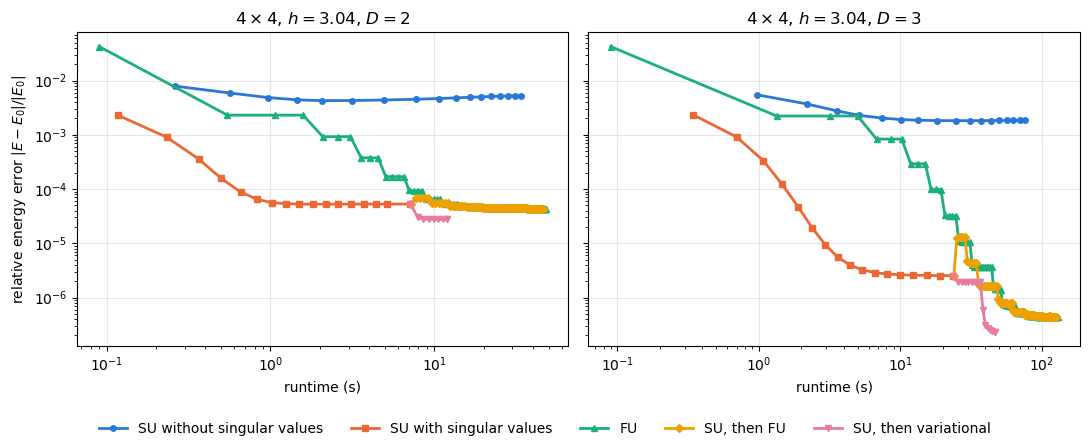

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, D in zip(axes, critical):
    plot_runtime(ax, critical[D], L, E0)
    ax.set_title(r"$4 \times 4$, $h = 3.04$, $D = %d$" % D)
axes[0].set_ylabel(r"relative energy error $|E - E_0| / |E_0|$")
shared_legend(fig, axes)
plt.show()

**Simple update without singular values.** It ends at a relative error of $5 \cdot 10^{-3}$ for $D = 2$ and $2 \cdot 10^{-3}$ for $D = 3$, two to three orders of magnitude above all other methods, and a larger bond dimension helps little. It also converges slowly: the convergence criterion is not reached for the small time steps, and the run uses about eight times as many steps as the simple update with singular values.

**Simple update with singular values.** With the same cost per step, the singular values on the neighboring bonds reduce the error to $5 \cdot 10^{-5}$ ($D = 2$) and $2.5 \cdot 10^{-6}$ ($D = 3$). It is the fastest method to reach a given accuracy.

**Full update.** The runs from the product state and from the simple update state end at the same energy: the result is a property of the fixed point of the update, not of the initial state. At $D = 2$ the full update gains only 20 % over the simple update; at $D = 3$ it gains a factor of 6. At the beginning of the evolution, FU from the product state follows the curve of the simple update at the same $\delta t$, only much more slowly. This is why starting the full update from the simple update state saves time. Right after the switch, the error of "SU, then FU" first rises. The simple update ended at $\delta t = 0.002$, and the full update restarts at $\delta t = 0.05$: within a few steps the state moves to the fixed point of this larger time step, with its Trotter error of $1.3 \cdot 10^{-5}$ for $D = 3$ (see the next figure). A smaller first time step for the full update should avoid this detour.

**Variational optimization.** It reaches the lowest energies, a factor of 1.6 ($D = 2$) to 2 ($D = 3$) below the full update. The imaginary time evolution does not minimize the energy for a given $D$: it ends where gates and truncations balance, and every truncation minimizes the distance of the states, not the energy.

### Dependence on the time step
The energies measured at the end of each $\delta t$, compared with the variational result (dashed line). For a fixed point of the exact Trotterized evolution, the eigenvalue of $H(\delta t)$ deviates from $E_0$ by $\mathcal{O}(\delta t^2)$ [dissertation, sec. 4.2.3]; the expectation value of $H$ in its eigenstate deviates only by $\mathcal{O}(\delta t^4)$, since the state differs from the ground state by $\mathcal{O}(\delta t^2)$. With truncation, the fixed point also depends on $\delta t$ through the truncation: a smaller $\delta t$ needs more steps and therefore more truncations for the same imaginary time.

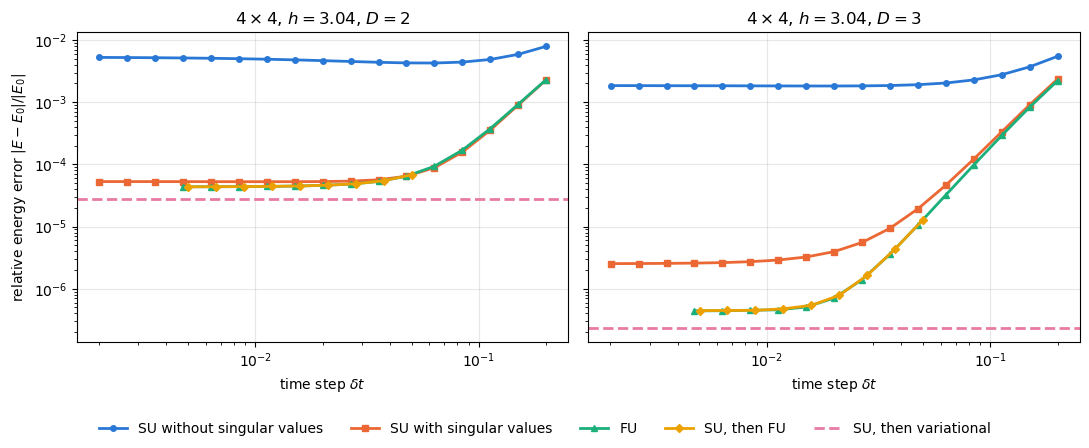

D = 2, SU with singular values: last dt 0.0020: relative error 5.3e-05, extrapolated to dt = 0: 5.3e-05
D = 2, SU, then FU:             last dt 0.0050: relative error 4.4e-05, extrapolated to dt = 0: 4.3e-05
D = 3, SU with singular values: last dt 0.0020: relative error 2.5e-06, extrapolated to dt = 0: 2.5e-06
D = 3, SU, then FU:             last dt 0.0050: relative error 4.4e-07, extrapolated to dt = 0: 4.4e-07


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, D in zip(axes, critical):
    plot_time_steps(ax, critical[D], E0)
    ax.set_title(r"$4 \times 4$, $h = 3.04$, $D = %d$" % D)
axes[0].set_ylabel(r"relative energy error $|E - E_0| / |E_0|$")
shared_legend(fig, axes)
plt.show()
for D, runs in critical.items():
    for method in ["SU", "SU+FU"]:
        r = runs[method]
        E_extra = extrapolate_dt(r["dts"][-2], r["stage_energies"][-2], r["dts"][-1], r["stage_energies"][-1])
        print("D = %d, %-24s last dt %.4f: relative error %.1e, extrapolated to dt = 0: %.1e"
              % (D, method_names[method] + ":", r["dts"][-1], abs(r["stage_energies"][-1] - E0) / abs(E0),
                 abs(E_extra - E0) / abs(E0)))

* For large $\delta t$, the simple update with singular values and the full update lie on the same line, with an error proportional to $\delta t^4$ (a factor of 3 per reduction of $\delta t$ by $0.75$): here the Trotter error dominates, and the truncation does not matter.
* For small $\delta t$, each method saturates at its own plateau, given by its truncation. The full update leaves the common line later and saturates lower. Reducing $\delta t$ further, or extrapolating to $\delta t = 0$, does not help on the plateau.
* The simple update without singular values is dominated by its truncation error for all $\delta t$. At $D = 2$ its energy even rises again for small $\delta t$: more steps mean more truncations.

### Bond dimension and magnetic field: $4 \times 4$
The remaining results were computed in advance with the functions of this notebook and are loaded from the folder `peps_ite_results`; together they need many hours. The commented lines in the next cell recompute them. The stored runs were computed with ten runs in parallel on one laptop, so their runtimes are two to five times longer than those of the same run in the cell above.

On the $4 \times 4$ lattice we compare three fields: $h = 2$ in the ordered phase, $h = 3.04$ close to the critical point of the infinite lattice, and $h = 4$ in the disordered phase. The Hamiltonian is symmetric under the flip of all spins, $\sigma^z_i \to -\sigma^z_i$. For $h < h_c$ the ground state of a finite lattice is the symmetric superposition of the two magnetized states, a "cat state" with long-range correlations; the first excited state is the antisymmetric superposition. Their energy difference decreases exponentially with the size of the lattice; on the $4 \times 4$ lattice at $h = 2$ it is still $E_1 - E_0 = 0.39$. The $x$-polarized initial state and all gates are symmetric, so the exact evolution keeps $\langle\sigma^z_i\rangle = 0$. The tables show $\langle\sigma^z\rangle$ of a site in the center of the lattice: a value different from zero means that the truncations have broken the symmetry (rounding errors are enough as a seed).

For $h = 3.04$ there are also results for $D = 5$ (all methods) and $D = 6$ (the two simple updates), measured with truncated boundaries, $\chi_\text{measure} = 100$. All stored runs had a common time limit. Only one run was stopped by it, the full update from the product state at $D = 5$; it is marked in the table and left out of the figures.

In [24]:
# parameters of the stored runs: (L, h, D): (chi, chi_measure)
stored = {(4, 3.04, 2): (8, 16), (4, 3.04, 3): (18, 81), (4, 3.04, 4): (32, 256), (4, 3.04, 5): (50, 100),
          (4, 3.04, 6): (72, 100),
          (4, 2.0, 2): (8, 16), (4, 2.0, 3): (18, 81), (4, 2.0, 4): (32, 256),
          (4, 4.0, 2): (8, 16), (4, 4.0, 3): (18, 81), (4, 4.0, 4): (32, 256),
          (6, 3.04, 2): (8, 64), (6, 3.04, 3): (18, 54), (6, 3.04, 4): (32, 48),
          (6, 2.0, 2): (8, 64), (6, 2.0, 3): (18, 54), (6, 4.0, 2): (8, 64), (6, 4.0, 3): (18, 54),
          (8, 3.04, 2): (8, 32), (8, 3.04, 3): (18, 36)}
# for (L, h, D), (chi, chi_measure) in stored.items():
#     save_runs(compare_methods(L, h, D, chi, chi_measure, product_fu=(L == 4)), L, h, D)
results = {key: load_runs(*key) for key in stored if load_runs(*key) is not None}

def bond_dimensions(L, h):
    return sorted(D for (L_, h_, D) in results if (L_, h_) == (L, h))

def finished(L, h, D, method):
    # the method was run for these parameters and not stopped by the time limit
    runs = results[(L, h, D)]
    return method in runs and runs[method].get("complete", True)

for h in [2.0, 3.04, 4.0]:
    print("4 x 4, h = %.2f, E0/V = %.8f" % (h, exact[(h, 4)] / 16))
    for D in bond_dimensions(4, h):
        print_runs(results[(4, h, D)], 4, D, exact[(h, 4)])

4 x 4, h = 2.00, E0/V = -2.24420360
   D = 2, SU without singular values: E/V = -2.19136972, relative error 2.4e-02, <sz> = +0.000,  4186 steps,     28 s


   D = 2, SU with singular values:    E/V = -2.23463835, relative error 4.3e-03, <sz> = -0.733,  4789 steps,     49 s


   D = 2, FU:                         E/V = -2.24228386, relative error 8.6e-04, <sz> = +0.000,   630 steps,    305 s


   D = 2, SU, then FU:                E/V = -2.24216978, relative error 9.1e-04, <sz> = -0.115,   540 steps,    299 s


   D = 2, SU, then variational:       E/V = -2.24341090, relative error 3.5e-04, <sz> = +0.000,    60 sweeps,    245 s


   D = 3, SU without singular values: E/V = -2.19132532, relative error 2.4e-02, <sz> = +0.220,  4269 steps,    154 s


... (42 outputs left out)

   D = 4, SU with singular values:    E/V = -4.09818298, relative error 2.4e-09, <sz> = -0.000,  1327 steps,    241 s


   D = 4, FU:                         E/V = -4.09818298, relative error 2.5e-09, <sz> = +0.000,   445 steps,   1914 s


   D = 4, SU, then FU:                E/V = -4.09818298, relative error 3.0e-09, <sz> = -0.000,   355 steps,   1886 s


   D = 4, SU, then variational:       E/V = -4.09818298, relative error 2.4e-09, <sz> = -0.000,     9 sweeps,    653 s


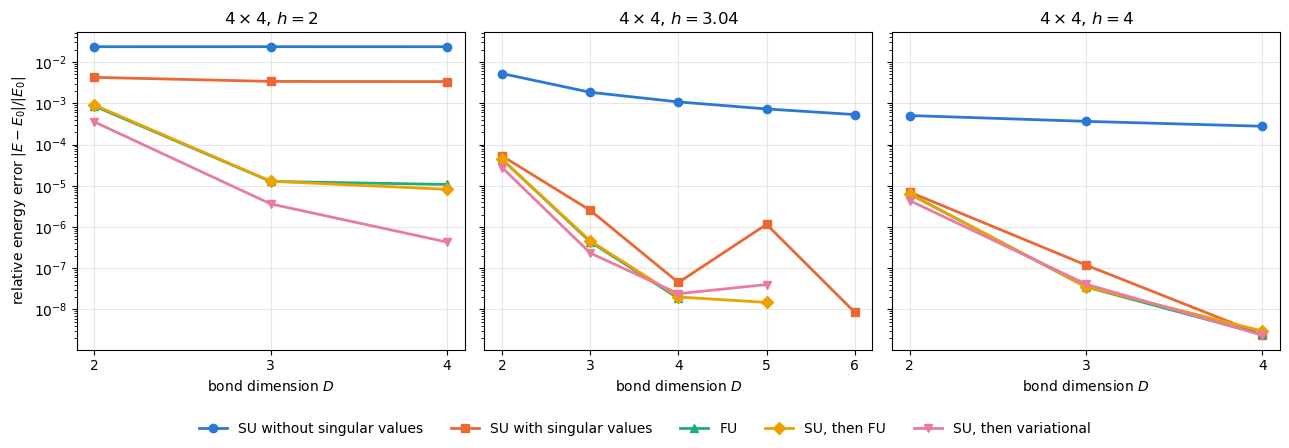

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True)
for ax, h in zip(axes, [2.0, 3.04, 4.0]):
    E0 = exact[(h, 4)]
    for method in method_names:
        points = [(D, abs(results[(4, h, D)][method]["E"] - E0) / abs(E0)) for D in bond_dimensions(4, h)
                  if finished(4, h, D, method)]
        if points:
            ax.semilogy(*zip(*points), marker=method_markers[method], markersize=6, linewidth=2,
                        color=method_colors[method], label=method_names[method])
    ax.set_title(r"$4 \times 4$, $h = %g$" % h)
    ax.set_xlabel("bond dimension $D$")
    ax.set_xticks(bond_dimensions(4, h))
    ax.grid(True, which="major", alpha=0.3)
axes[0].set_ylabel(r"relative energy error $|E - E_0| / |E_0|$")
shared_legend(fig, axes)
plt.show()

**Disordered phase and critical region ($h = 4$ and $h = 3.04$), $D \le 4$.** The errors of the simple update with singular values, the full update and the variational optimization fall by one to two orders of magnitude with every step in $D$, and the three methods stay within about one order of magnitude of each other. The full update is better than the simple update by a factor of up to 6, and from $D = 3$ ($h = 4$) or $D = 4$ ($h = 3.04$) on it reaches the energies of the variational optimization. The correlations are short-ranged here, and the product environment of the simple update is a good approximation. All states are symmetric, $\langle\sigma^z\rangle = 0$. Relative errors of $10^{-9}$ ($h = 4$, $D = 4$) are at the limit of what this comparison can resolve.

**$D = 5$ and $D = 6$ at $h = 3.04$.** The simple update with singular values does not improve monotonically with $D$: its error is $4.5 \cdot 10^{-8}$ at $D = 4$, $1.2 \cdot 10^{-6}$ at $D = 5$ and $9 \cdot 10^{-9}$ at $D = 6$. The value at $D = 5$ does not change with the boundary bond dimension of the measurement, so it is a property of the state. We have no explanation for it; nothing guarantees that the fixed point of the simple update improves with every step in $D$. The full update repairs this state: started from it, it reaches $1.5 \cdot 10^{-8}$, slightly below its result at $D = 4$, and a factor of 80 below the simple update. The full update from the product state behaved differently at $D = 5$: for the small time steps its energy fluctuated around an error of $10^{-6}$, and the time limit stopped the run during the last time step. The variational optimization, started from the simple update state, ended at $4 \cdot 10^{-8}$, above its result at $D = 4$. So above $D = 4$, at errors of $10^{-8}$, the results on this small lattice are no longer systematic.

**Ordered phase ($h = 2$).** The simple update with singular values does not improve with $D$: its error stays at $3$ to $4 \cdot 10^{-3}$. The reason is visible in the magnetization, $\langle\sigma^z\rangle \approx -0.7$: the simple update has broken the symmetry and ends in a magnetized state. Its product environment acts like a mean field, which favors a magnetization. A magnetized state is a superposition of the ground state and the first excited state, and its energy lies between $E_0$ and $E_1$; no bond dimension can repair this. The full update from the product state keeps the symmetry, $|\langle\sigma^z\rangle| \le 10^{-3}$. Its error falls from $9 \cdot 10^{-4}$ at $D = 2$ to $1.3 \cdot 10^{-5}$ at $D = 3$ and changes little at $D = 4$ ($1.1 \cdot 10^{-5}$). Started from the magnetized simple update state, it removes most of the magnetization ($\langle\sigma^z\rangle = -0.12$ at $D = 2$, $-0.01$ at $D = 3$ and $4$) and reaches about the same energy. The variational optimization is the most accurate method here, by a factor of 20 at $D = 4$.

**Simple update without singular values.** At $h = 2$ it stays at a relative error of $2.4 \cdot 10^{-2}$ for every $D$. This is practically the energy of the best product state ($D = 1$), which has a relative error of $2.41 \cdot 10^{-2}$: the update makes almost no use of the bond dimension. For the other fields its error is 70 to $10^5$ times larger than that of the simple update with singular values.

### Boundary bond dimension of the full update
The full update needs the environment of every bond, contracted with boundary MPS of bond dimension $\chi$. The table shows the final energy of "SU, then FU" on the $4 \times 4$ lattice at $h = 3.04$ for several $\chi$, up to exact boundaries ($\chi = D^4$).

In [26]:
h, E0 = 3.04, exact[(3.04, 4)]
for D in bond_dimensions(4, h):
    name = os.path.join(results_folder, "chi_L4_h%.2f_D%d.json" % (h, D))
    if os.path.exists(name) and "SU+FU" in results[(4, h, D)]:
        with open(name) as f:
            by_chi = {int(chi): r for chi, r in json.load(f).items()}
        by_chi[stored[(4, h, D)][0]] = results[(4, h, D)]["SU+FU"]
        print("D = %d, SU with singular values: relative error %.1e" % (D, abs(results[(4, h, D)]["SU"]["E"] - E0) / abs(E0)))
        for chi in sorted(by_chi):
            r = by_chi[chi]
            print("   SU, then FU with chi = %3d: relative error %.1e, %6.0f s%s"
                  % (chi, abs(r["E"] - E0) / abs(E0), r["runtime"], "" if r.get("complete", True) else " (stopped at the time limit)"))

D = 2, SU with singular values: relative error 5.3e-05
   SU, then FU with chi =   4: relative error 4.4e-05,    197 s
   SU, then FU with chi =   8: relative error 4.4e-05,    184 s
   SU, then FU with chi =  16: relative error 4.4e-05,    217 s
D = 3, SU with singular values: relative error 2.5e-06
   SU, then FU with chi =   9: relative error 4.4e-07,    615 s
   SU, then FU with chi =  18: relative error 4.6e-07,    622 s
   SU, then FU with chi =  81: relative error 4.4e-07,    758 s
D = 4, SU with singular values: relative error 4.5e-08
   SU, then FU with chi =  16: relative error 3.0e-08,   2171 s
   SU, then FU with chi =  32: relative error 2.0e-08,   2157 s
   SU, then FU with chi =  64: relative error 1.9e-08,   2505 s


The result of the full update depends only weakly on $\chi$. For $D = 2$ and $D = 3$ the errors for $\chi = D^2$, $2D^2$ and exact boundaries ($\chi = D^4$) agree within 5 %. For $D = 4$, $\chi = D^2$ gives $3.0 \cdot 10^{-8}$, while $\chi = 2D^2$ and $4D^2$ give $2.0 \cdot 10^{-8}$ and $1.9 \cdot 10^{-8}$. The remaining difference to the variational optimization is therefore not caused by the approximate environment; it is a property of the fixed point of the update.

### Larger lattices: $6 \times 6$ and $8 \times 8$
Exact diagonalization is no longer possible. We compare the energies with the lowest energy $E_\text{min}$ of all runs for the same lattice and field. The boundaries of the measurements are truncated here ($\chi_\text{measure}$ in the list above), so the measured energies are not strict upper bounds any more. The full update from the product state was only run for some of the lattices.

In [27]:
def lowest_energy(L, h):
    return min(results[(L, h, D)][method]["E"] for D in bond_dimensions(L, h) for method in method_names
               if method in results[(L, h, D)])

large = sorted({(L, h) for (L, h, D) in results if L > 4})
for (L, h) in large:
    print("%d x %d, h = %.2f, lowest energy per site: %.8f" % (L, L, h, lowest_energy(L, h) / L**2))
    for D in bond_dimensions(L, h):
        print_runs(results[(L, h, D)], L, D)

6 x 6, h = 2.00, lowest energy per site: -2.31615119
   D = 2, SU without singular values: E/V = -2.28687419, <sz> = +0.000,  3131 steps,     88 s


   D = 2, SU with singular values:    E/V = -2.31603204, <sz> = -0.837,  3489 steps,    136 s


   D = 2, SU, then FU:                E/V = -2.31611437, <sz> = -0.834,   485 steps,    927 s


   D = 2, SU, then variational:       E/V = -2.31612636, <sz> = -0.833,     9 sweeps,    367 s


   D = 3, SU without singular values: E/V = -2.28687419, <sz> = +0.467,  3195 steps,    460 s


   D = 3, SU with singular values:    E/V = -2.31613372, <sz> = +0.835,  1278 steps,    687 s


... (29 outputs left out)

   D = 3, SU without singular values: E/V = -3.14271109, <sz> = -0.589,  8500 steps,   2204 s


   D = 3, SU with singular values:    E/V = -3.20126389, <sz> = -0.000,  1307 steps,   1287 s


   D = 3, SU, then FU:                E/V = -3.20131451, <sz> = -0.000,   470 steps,   9585 s


   D = 3, SU, then variational:       E/V = -3.20131903, <sz> = -0.000,    20 sweeps,   8561 s


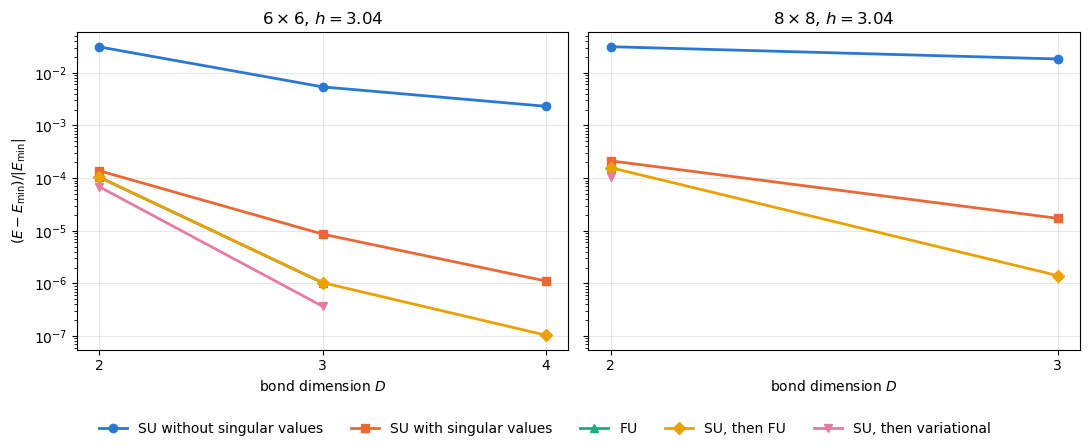

In [28]:
panels = [(L, h) for (L, h) in large if h == 3.04]
fig, axes = plt.subplots(1, len(panels), figsize=(5.5 * len(panels), 4.5), sharey=True, squeeze=False)
for ax, (L, h) in zip(axes[0], panels):
    Emin = lowest_energy(L, h)
    for method in method_names:
        points = [(D, (results[(L, h, D)][method]["E"] - Emin) / abs(Emin)) for D in bond_dimensions(L, h)
                  if finished(L, h, D, method)]
        points = [(D, e) for D, e in points if e > 0]   # the lowest energy itself cannot be shown on a logarithmic axis
        if points:
            ax.semilogy(*zip(*points), marker=method_markers[method], markersize=6, linewidth=2,
                        color=method_colors[method], label=method_names[method])
    ax.set_title(r"$%d \times %d$, $h = %g$" % (L, L, h))
    ax.set_xlabel("bond dimension $D$")
    ax.set_xticks(bond_dimensions(L, h))
    ax.grid(True, which="major", alpha=0.3)
axes[0][0].set_ylabel(r"$(E - E_\mathrm{min}) / |E_\mathrm{min}|$")
shared_legend(fig, axes[0])
plt.show()

* At $h = 3.04$, the order of the methods is the same as on the $4 \times 4$ lattice: simple update without singular values, with singular values, full update, variational optimization. At $h = 4$ and $D = 3$ on the $6 \times 6$ lattice, the last three agree to 7 digits.
* The gain of the full update over the simple update grows with the size of the lattice. At $D = 2$ and $h = 3.04$, the relative difference of their energies is $9 \cdot 10^{-6}$ on $4 \times 4$, $3 \cdot 10^{-5}$ on $6 \times 6$ and $5.5 \cdot 10^{-5}$ on $8 \times 8$ sites; at $D = 3$ it is $2 \cdot 10^{-6}$, $8 \cdot 10^{-6}$ and $1.6 \cdot 10^{-5}$. A larger lattice at this field is closer to the critical point of the infinite system, with longer correlations, which the product environment of the simple update does not contain.
* A larger bond dimension can compensate for the simpler update: on the $6 \times 6$ lattice, the simple update with $D = 4$ reaches the energy of the full update with $D = 3$.
* The simple update without singular values gains little over a product state: at $D = 2$ on the $6 \times 6$ lattice its energy per site is $-3.093$, compared with $-3.070$ for the best product state and $-3.192$ for the other methods. On the $8 \times 8$ lattice at $D = 3$ it ends in a magnetized state ($\langle\sigma^z\rangle = -0.59$).
* At $h = 2$ on the $6 \times 6$ lattice, the simple update is magnetized again, and now the full update and the variational optimization, which start from this state, stay magnetized. The energy difference $E_1 - E_0$ is much smaller than on the $4 \times 4$ lattice, so the magnetized state is almost degenerate with the symmetric ground state and nothing drives the state back.

## 10. Summary
* Imaginary time evolution projects a PEPS onto the ground state with two-site gates. Every gate is followed by a truncation of the bond, and the quality of the truncation depends on how well the **environment** of the bond is known.
* **Without environment** (an SVD of the two tensors alone), the result is poor: errors of $3 \cdot 10^{-4}$ to $2 \cdot 10^{-2}$ that improve only slowly with $D$, in the ordered phase hardly better than a product state. For an MPS the same update is optimal, because the canonical form makes the environment trivial; a PEPS has no such form.
* The **simple update** uses the singular values of the neighboring bonds as environment. At the same cost per step, the error is lower by up to five orders of magnitude. It is the method with the best ratio of accuracy and cost, and the natural first stage of any calculation. It fails where the correlations are long-ranged: it breaks the symmetry in the ordered phase, and it loses accuracy close to the critical point as the lattice grows.
* The **full update** contracts the environment of the whole network with boundary MPS. It repairs these failures: on the $4 \times 4$ lattice it gains more than two orders of magnitude in the error in the ordered phase and up to a factor of 6 at $h \ge 3.04$ and $D \le 4$ (a factor of 80 at $D = 5$, where the simple update is unexpectedly poor). The runtime is five to ten times longer. It should be started from the simple update state and needs small time steps ($\delta t \lesssim 0.01$) to reach its plateau. A boundary bond dimension of $\chi = 2D^2$ was sufficient here.
* The **variational optimization** minimizes the energy directly and gives the lowest energies in most cases. The time evolution ends in a fixed point of gates and truncations instead; for $h \ge 3.04$ and $D \ge 3$ the full update comes within a factor of 2 of the variational result or reaches it.
* All methods share the same building blocks: the PEPS, the boundary MPS and the measurement of `PEPS_variational.ipynb`. For fermions, the tensors additionally carry a parity, and the algorithms keep their form [dissertation, chapter 4].